# NYC Taxi — Öğrenci 3 ders gösterimi

Ocak–Mayıs 2026 dönemindeki **17.210.961 temiz Yellow Taxi kaydını** inceledik. Her kayıt gerçekleşmiş bir yolculuğu temsil eder. Saat ve tarihler New York yerel saatidir.

**Ekipte veri akışı.** Öğrenci 1 veriyi hazırlar. Öğrenci 2 temiz Parquet dosyalarını üretir ve biniş zamanından `pickup_hour` (biniş saati) ile `pickup_dow` (haftanın günü) alanlarını çıkarır. Öğrenci 3, bu dosyalarla saat, gün, bölge ve ödeme özetlerini hesaplar.

**İçerik** · [Saat](#saat-analizi) · [Gün](#gun-analizi) · [Bölge](#bolge-analizi) · [Ödeme](#odeme-analizi) · [Sonuç kontrolü](#sonuc-kontrolu)

Grafikler ve tablolar notebook’ta kayıtlıdır. Hesapları yeniden üretmek için ekip deposundaki notebook’u temiz Parquet dosyaları ve TLC bölge sözlüğü hazırken proje Python ortamıyla açın ve **Restart Kernel and Run All Cells** (çekirdeği yeniden başlat ve tüm hücreleri çalıştır) seçeneğini kullanın. İlk kod hücresi sorguları çalıştırır ve işi bitince Spark oturumunu kapatır. Bölümlerdeki PySpark hücreleri bu sorguların kaynak kodunu gösterir. Süre tabloları ayrı deneylerden kaydedildi. [25 Nisan’ın ayrıntılı karşılaştırması](#pik-gun-kontrolu) gün bölümünde. [Canlı sorgu ve grafik çalışma alanı](#canli-sorgu).

**Ortak proje ortamı.** Depoyu ve proje ortamını README'deki hızlı başlangıca göre hazırlayın. Temiz veri eksikse proje kökünde `python -m src.fetch_data` çalıştırın. TLC bölge sözlüğünü tek başına indirme komutu README’nin 8. bölümündedir. Notebook’u proje kökünden veya `notebooks` klasöründen açın.


In [1]:
import inspect
import re
from contextlib import redirect_stdout
from io import StringIO

from pyspark.sql import Window, functions as F
import os
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))
from src import aggregate_trips as spark_queries
from src import compare_aggregation as kiyas
from src.config import FIGURES_DIR
from src.spark_session import DEFAULT_HADOOP_HOME, DEFAULT_JAVA_HOME, get_spark

figures = FIGURES_DIR
BLUE, ORANGE = "#245B83", "#B34F27"
plt.rcParams.update({"font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.axisbelow": True, "grid.color": "#E1E6EB"})

def tr_int(value):
    return f"{value:,.0f}".replace(",", ".")

def tr_dec(value, digits=2):
    return f"{value:.{digits}f}".replace(".", ",")

def show_figure(fig):
    plt.show()
    plt.close(fig)

def sorgulari_goster(spark_functions):
    listing = "\n\n".join(inspect.getsource(function).strip() for function in spark_functions)
    display(Markdown(f"**PySpark**\n\n```python\n{listing}\n```"))

def bolge_birlestirme_planlari(spark, files):
    settings = {
        "spark.sql.adaptive.enabled": "false",
        "spark.sql.autoBroadcastJoinThreshold": "-1",
        "spark.sql.shuffle.partitions": "200",
    }
    previous = {key: spark.conf.get(key) for key in settings}
    counts = None
    lookup = None
    try:
        for key, value in settings.items():
            spark.conf.set(key, value)
        counts = (spark.read.parquet(*files).groupBy("PULocationID").count()
                  .withColumnRenamed("count", "trip_count").persist())
        lookup = (spark.read.option("header", True).csv(str(kiyas.ZONE_LOOKUP_PATH))
                  .select(F.col("LocationID").cast("int").alias("PULocationID"),
                          F.col("Borough").alias("borough"),
                          F.col("Zone").alias("pickup_zone")).persist())
        assert counts.count() == 260 and lookup.count() == 265
        joins = [
            ("Broadcast", counts.join(F.broadcast(lookup), "PULocationID", "left"),
             ("BroadcastHashJoin", "BroadcastExchange")),
            ("Sort-merge", counts.hint("merge").join(lookup.hint("merge"), "PULocationID", "left"),
             ("SortMergeJoin", "Exchange hashpartitioning", "Sort [")),
        ]
        plan_table, results = [], []
        for label, query, operators in joins:
            rows = query.collect()
            results.append(sorted(rows, key=lambda row: row.PULocationID))
            captured = StringIO()
            with redirect_stdout(captured):
                query.explain()
            # Cached input subplans can include the earlier grouping's Exchange.
            # Read only the executed join tree, above each cached input.
            visible = []
            for line in captured.getvalue().splitlines():
                # Each physical-plan tree level occupies three characters.
                prefix = re.match(r"^(?:[ |:]  |[+:]- )*", line).group()
                if len(prefix) <= 9 and any(op in line for op in operators):
                    visible.append(line[len(prefix):])
            assert all(any(operator in line for line in visible) for operator in operators)
            for line in visible:
                plan_table.append((label, line.strip()))
        assert results[0] == results[1] and len(results[0]) == 260
        assert sum(row.trip_count for row in results[0]) == kiyas.CLEAN_ROWS
        return pd.DataFrame(plan_table, columns=["Yöntem", "Gerçek Spark planında görülen satır"])
    finally:
        if lookup is not None:
            lookup.unpersist(blocking=True)
        if counts is not None:
            counts.unpersist(blocking=True)
        for key, value in previous.items():
            spark.conf.set(key, value)

import shutil
java_executable = shutil.which("java")
if not os.environ.get("NYC_JAVA_HOME") and not Path(DEFAULT_JAVA_HOME).is_dir():
    configured_java = os.environ.get("JAVA_HOME")
    if configured_java and Path(configured_java).is_dir():
        os.environ["NYC_JAVA_HOME"] = configured_java
    elif java_executable:
        os.environ["NYC_JAVA_HOME"] = str(Path(java_executable).resolve().parent.parent)
    else:
        raise RuntimeError("Java bulunamadı; ortak kurulum için README’nin 3. bölümüne bakın.")
local_hadoop = root / ".venv-tools" / "hadoop"
if not os.environ.get("HADOOP_HOME") and not Path(DEFAULT_HADOOP_HOME).is_dir() and local_hadoop.is_dir():
    os.environ["HADOOP_HOME"] = str(local_hadoop)
try:
    files = kiyas.clean_parquet_files()
except AssertionError as exc:
    raise FileNotFoundError("Beş temiz Parquet dosyası bulunamadı. Temiz veri kurulumu için README’nin 0. bölümüne bakın.") from exc
if not kiyas.ZONE_LOOKUP_PATH.is_file():
    raise FileNotFoundError("TLC bölge sözlüğü bulunamadı. İndirme komutu için README’nin 8. bölümüne bakın.")
spark = get_spark("ogrenci-3-tam-kiyas", driver_memory="3g", cores="2")
try:
    spark.sparkContext.setLogLevel("ERROR")
    assert spark.sparkContext.master == "local[2]"
    preview_input = spark.read.parquet(*files).select(
        "tpep_pickup_datetime", "pickup_hour", "pickup_dow", "PULocationID",
        "payment_type", "fare_amount", "tip_amount", "total_amount"
    )
    girdi_semalari = dict(preview_input.dtypes)
    girdi_ornegi = (preview_input.filter((F.col("pickup_hour") == 8) & (F.col("payment_type") == 1)).limit(1)
                    .unionByName(preview_input.filter((F.col("pickup_hour") == 8) & (F.col("payment_type") == 0)).limit(1))
                    .unionByName(preview_input.filter((F.col("pickup_hour") == 18) & (F.col("payment_type") == 1)).limit(1))
                    .unionByName(preview_input.filter((F.col("pickup_hour") == 18) & (F.col("payment_type") == 0)).limit(1))
                    .toPandas())
    assert len(girdi_ornegi) == 4 and set(girdi_ornegi["payment_type"]) == {0, 1}
    girdi_ornegi["tpep_pickup_datetime"] = girdi_ornegi["tpep_pickup_datetime"].dt.strftime("%Y-%m-%d %H:%M:%S")
    spark_tables, _ = kiyas.spark_reports(spark, files, kiyas.ZONE_LOOKUP_PATH)
    kiyas.verify_full_scope(spark_tables)
    spark_plan = kiyas.hourly_spark_plan(spark)
    saturdays = kiyas.saturday_context(spark)
    join_plans = bolge_birlestirme_planlari(spark, files)
finally:
    spark.stop()

hour = spark_tables["hour"]
day = spark_tables["day"].assign(pickup_date=lambda x: pd.to_datetime(x["pickup_date"]))
zone = spark_tables["zone"]
payment = spark_tables["payment"]
print("Altı PySpark sonuç tablosu ve toplamlar doğrulandı.")


Altı PySpark sonuç tablosu ve toplamlar doğrulandı.


In [2]:
display(Markdown(
    "### Girdi nasıl görünüyor?\n\n"
    "Temiz tablodan saat 08.00 ve 18.00 için birer kredi kartı ve Flex Fare kaydı seçildi. Her satır bir biniştir. "
    "`pickup_dow` için Pazar 1, Cumartesi 7’dir."
))
gorunum = girdi_ornegi.copy()
for alan in ("fare_amount", "tip_amount", "total_amount"):
    gorunum[alan] = gorunum[alan].map(lambda x: "—" if pd.isna(x) else f"{x:.2f}")
display(gorunum.rename(columns={
    col: f"{col} ({girdi_semalari[col]})" for col in girdi_ornegi.columns
}))

### Girdi nasıl görünüyor?

Temiz tablodan saat 08.00 ve 18.00 için birer kredi kartı ve Flex Fare kaydı seçildi. Her satır bir biniştir. `pickup_dow` için Pazar 1, Cumartesi 7’dir.

,tpep_pickup_datetime (timestamp_ntz),pickup_hour (int),pickup_dow (int),PULocationID (int),payment_type (bigint),fare_amount (double),tip_amount (double),total_amount (double)
0,2026-05-01 08:00:00,8,6,151,1,6.50,2.10,12.60
1,2026-05-01 08:00:00,8,6,158,0,19.80,0.00,35.26
2,2026-05-01 18:00:01,18,6,79,1,19.10,5.00,31.35
3,2026-05-01 18:00:00,18,6,166,0,24.21,0.00,28.96


<a id="saat-analizi"></a>

## Saat

**Hangi saatte en çok biniş var?** `pickup_hour` (biniş saati) aynı olan yolculukları birlikte sayıyoruz.

```python
trips.groupBy("pickup_hour").count()
```

**Sonuç:** 18.00–18.59, beş aylık toplamda **1.150.635** binişle ilk sırada.

18.00’deki yoğunluk, iş çıkışı ve akşam hareketliliğiyle ilişkili olabilir. Önceki NYC taksi araştırmalarında da 17.00–20.00 arasında yoğunluk görülmüştür. [NYC taksi araştırması](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0259694)

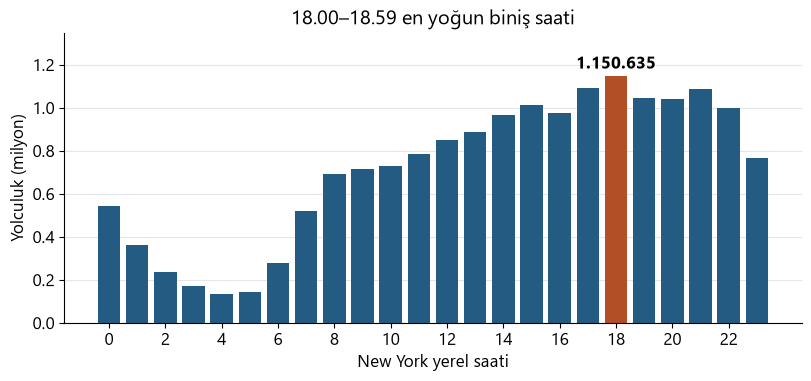

In [3]:
hourly = hour.sort_values("pickup_hour")
peak = hourly.loc[hourly.trip_count.idxmax()]
fig, ax = plt.subplots(figsize=(8, 3.7), layout="constrained")
colors = [ORANGE if value == peak.pickup_hour else BLUE for value in hourly.pickup_hour]
ax.bar(hourly.pickup_hour, hourly.trip_count / 1_000_000, color=colors)
ax.set(title=f"{int(peak.pickup_hour):02d}.00–{int(peak.pickup_hour):02d}.59 en yoğun biniş saati", xlabel="New York yerel saati",
       ylabel="Yolculuk (milyon)", ylim=(0, 1.35))
ax.set_xticks(range(0, 24, 2))
ax.grid(axis="y")
ax.annotate(tr_int(peak.trip_count), (peak.pickup_hour, peak.trip_count / 1_000_000),
            xytext=(0, 5), textcoords="offset points", ha="center", fontweight="bold")
show_figure(fig)

### Aggregation (gruplu özetleme) nasıl çalışır?

`groupBy("pickup_hour").count()` aynı `pickup_hour` (biniş saati) değerindeki yolculukları gruplar ve her grupta kaç kayıt olduğunu sayar. Görselde altı biniş üç özet satırına iner. Tam veride 24 saat için 24 özet satırı çıkar.

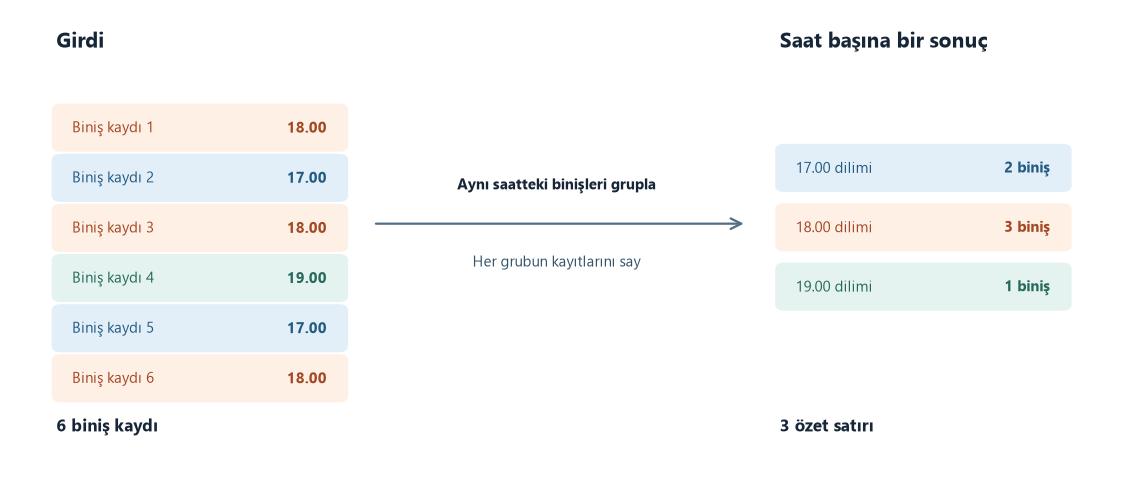

In [4]:
from matplotlib.patches import FancyBboxPatch

ornek_saatler = (18, 17, 18, 19, 17, 18)
ornek_gruplar = pd.DataFrame({"pickup_hour": ornek_saatler}).groupby("pickup_hour").size()
assert list(ornek_gruplar.items()) == [(17, 2), (18, 3), (19, 1)]
renkler = {17: ("#E3EFF8", "#245B83"), 18: ("#FFF0E6", "#A34824"),
           19: ("#E4F3EF", "#28695D")}

fig, ax = plt.subplots(figsize=(11.2, 4.7), layout="constrained")
ax.set(xlim=(0, 12), ylim=(0, 7))
ax.set_axis_off()
ax.text(0.5, 6.42, "Girdi", fontsize=15, weight="bold", color="#172637")
ax.text(8.31, 6.42, "Saat başına bir sonuç", fontsize=15, weight="bold", color="#172637")

def satir(x, y, hour_value, label, count):
    fill, ink = renkler[hour_value]
    ax.add_patch(FancyBboxPatch((x, y), 3.1, 0.63, boxstyle="round,pad=0.05,rounding_size=.1",
                                facecolor=fill, edgecolor="none"))
    ax.text(x + .17, y + .30, label, fontsize=11, color=ink, va="center")
    ax.text(x + 2.92, y + .30, count, fontsize=11, weight="bold", color=ink, ha="right", va="center")

for row, hour_value in enumerate(ornek_saatler, 1):
    satir(.5, 5.65 - .76 * row, hour_value, f"Biniş kaydı {row}", f"{hour_value:02d}.00")
for index, (hour_value, count) in enumerate(ornek_gruplar.items()):
    satir(8.31, 4.28 - .90 * index, hour_value, f"{hour_value:02d}.00 dilimi", f"{count} biniş")

ax.annotate("", xy=(7.95, 3.75), xytext=(3.92, 3.75),
            arrowprops={"arrowstyle": "->", "lw": 1.6, "color": "#536D82", "mutation_scale": 19})
ax.text(5.9, 4.27, "Aynı saatteki binişleri grupla", fontsize=11, weight="bold",
        ha="center", color="#172637")
ax.text(5.9, 3.10, "Her grubun kayıtlarını say", fontsize=11, ha="center", color="#36536A")
ax.text(.5, .60, "6 biniş kaydı", fontsize=12, weight="bold", color="#172637")
ax.text(8.31, .60, "3 özet satırı", fontsize=12, weight="bold", color="#172637")
show_figure(fig)


### 18.00 nasıl öne çıkıyor?

Hafta içi günlerinin toplamında 21.00 az farkla önde. Hafta sonu 18.00’ın farkı daha büyük ve dönem toplamını öne geçiriyor. Grafikte her grubun biniş toplamı o grubun gün sayısına bölündü. Dönemde hafta içinden 107, hafta sonundan 44 gün var.

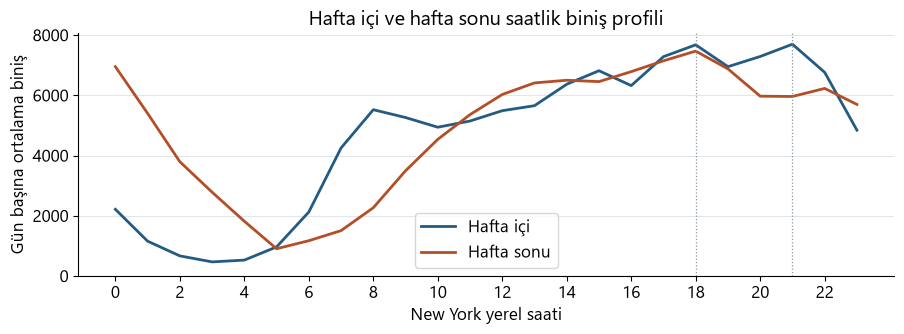

Tablo, 18.00 ve 21.00 için dönem toplamlarını gösterir.

,18.00 toplamı,21.00 toplamı,18.00 ile 21.00 farkı
Dönem,,,
Hafta içi,821.861,823.992,-2.131
Hafta sonu,328.774,262.452,66.322


In [5]:
pattern = spark_tables["pattern"].copy()
pattern["weekday"] = (pattern["pickup_dow"] + 5) % 7
weekdays = ["Pazartesi", "Salı", "Çarşamba", "Perşembe", "Cuma", "Cumartesi", "Pazar"]
days_per_weekday = day["pickup_date"].dt.dayofweek.value_counts()

by_day_type = {}
for label, indices in (("Hafta içi", range(5)), ("Hafta sonu", (5, 6))):
    subset = pattern.loc[pattern["weekday"].isin(indices)]
    by_day_type[label] = (subset.groupby("pickup_hour")["trip_count"].sum()
                          / days_per_weekday.reindex(indices).sum())
type_profile = pd.DataFrame(by_day_type)
ax = type_profile.plot(figsize=(9.2, 3.5), color=[BLUE, ORANGE], linewidth=2)
ax.set(title="Hafta içi ve hafta sonu saatlik biniş profili",
       xlabel="New York yerel saati", ylabel="Gün başına ortalama biniş", ylim=(0, None))
ax.set_xticks(range(0, 24, 2))
for hour_mark in (18, 21):
    ax.axvline(hour_mark, color="#8797A3", linewidth=0.9, linestyle=":")
ax.grid(axis="y")
plt.tight_layout()
plt.show()

comparison = []
for label, indices in (("Hafta içi", range(5)), ("Hafta sonu", (5, 6))):
    two = (pattern.loc[pattern["weekday"].isin(indices) & pattern["pickup_hour"].isin([18, 21])]
           .groupby("pickup_hour")["trip_count"].sum())
    comparison.append([label, tr_int(two[18]), tr_int(two[21]), tr_int(two[18] - two[21])])
display(Markdown("Tablo, 18.00 ve 21.00 için dönem toplamlarını gösterir."))
display(pd.DataFrame(comparison, columns=["Dönem", "18.00 toplamı", "21.00 toplamı", "18.00 ile 21.00 farkı"])
        .set_index("Dönem"))


Hafta içi 21.00 **2.131** biniş önde. Hafta sonu 18.00’ın **66.322** binişlik üstünlüğü bu farkı kapatıyor. Bu, genel zirvenin nasıl oluştuğunu gösterir. Yolculuk amacı TLC kaydında bulunmadığından iş çıkışının veya turizmin katkısını ölçemiyoruz.

### Hafta günü ve saat birlikte

Isı haritasında renk bir günün o saatindeki **ortalama** binişi gösterir. Örneğin Perşembe 21.00 hücresi, beş ay boyunca Perşembe 21.00–21.59’daki binişlerin toplamının Perşembe sayısına bölünmesiyle bulunur. Bölümün başındaki saat grafiğindeki çubuklar ise dönem toplamıdır.

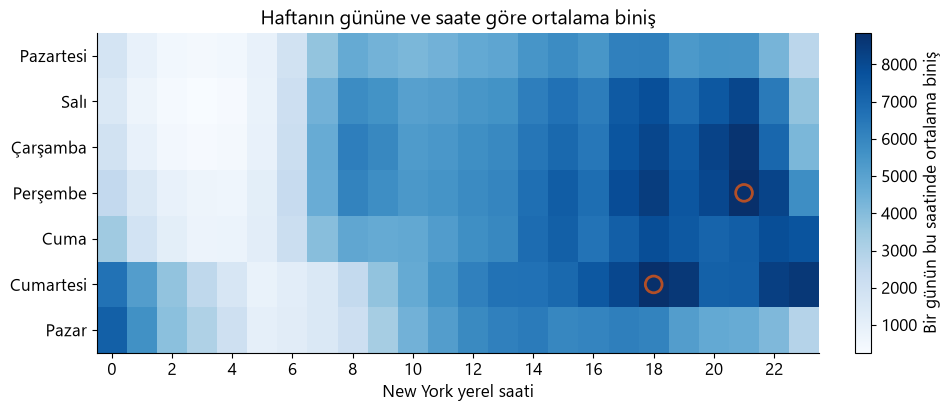

,Hafta günü,Saat aralığı,Ortalamaya giren gün,Ortalama biniş
Dönem,,,,
Hafta içi,Perşembe,21.00–21.59,22,8.830
Hafta sonu,Cumartesi,18.00–18.59,22,8.853


In [6]:
pattern["mean_trips"] = pattern["trip_count"] / pattern["weekday"].map(days_per_weekday)
matrix = pattern.pivot(index="weekday", columns="pickup_hour", values="mean_trips")
fig, ax = plt.subplots(figsize=(9.4, 4.0), layout="constrained")
image = ax.imshow(matrix, aspect="auto", cmap="Blues")
ax.set(title="Haftanın gününe ve saate göre ortalama biniş", xlabel="New York yerel saati")
ax.set_xticks(range(0, 24, 2))
ax.set_yticks(range(7), weekdays)
peak_cells = []
for period, subset in (("Hafta içi", matrix.iloc[:5]), ("Hafta sonu", matrix.iloc[5:])):
    weekday, hour_index = subset.stack().idxmax()
    ax.scatter(hour_index, weekday, s=145, facecolors="none", edgecolors=ORANGE, linewidths=2)
    peak_cells.append({
        "Dönem": period,
        "Hafta günü": weekdays[weekday],
        "Saat aralığı": f"{hour_index:02d}.00–{hour_index:02d}.59",
        "Ortalamaya giren gün": int(days_per_weekday[weekday]),
        "Ortalama biniş": tr_int(matrix.loc[weekday, hour_index]),
    })
fig.colorbar(image, ax=ax, label="Bir günün bu saatinde ortalama biniş")
show_figure(fig)

display(pd.DataFrame(peak_cells).set_index("Dönem"))


Turuncu halkalar hafta içi Perşembe 21.00 ve hafta sonu Cumartesi 18.00 piklerini gösterir. Akşam ve hafta sonu hareketliliği bu yoğunlukta etkili olabilir. Her hücre, beş ay boyunca ilgili gün ve saatin ortalamasıdır.

In [7]:
sorgulari_goster([spark_queries.hourly_trip_counts, spark_queries.weekday_hour_trip_counts])


**PySpark**

```python
def hourly_trip_counts(trips: DataFrame) -> DataFrame:
    """Count pickups by New York local hour, busiest first."""
    return (
        trips.groupBy("pickup_hour")
        .count()
        .withColumnRenamed("count", "trip_count")
        .orderBy(F.desc("trip_count"), F.asc("pickup_hour"))
    )

def weekday_hour_trip_counts(trips: DataFrame) -> DataFrame:
    """Count pickups by Spark weekday (Sunday=1) and New York local hour."""
    return (
        trips.groupBy("pickup_dow", "pickup_hour")
        .count()
        .withColumnRenamed("count", "trip_count")
        .orderBy("pickup_dow", "pickup_hour")
    )
```

### Spark saat sayımını nasıl çalıştırdı?

Yukarıdaki altı örnek binişin ilk üçü A bölümüne, son üçü B bölümüne düşsün. Gerçek sorguda Spark, her bölümde ara sayım yapar. Sonra `Exchange` (veriyi bölümler arasında yeniden dağıtma), aynı saate ait ara sayımları bir araya getirir. Böylece 18.00 için 2 + 1 = **3 biniş** bulunur.

| `pickup_hour` (biniş saati) | A bölümünün ara sayımı | B bölümünün ara sayımı | Sonuç |
| --- | ---: | ---: | ---: |
| 17 | 1 | 1 | 2 |
| 18 | 2 | 1 | **3** |
| 19 | 0 | 1 | 1 |

Aşağıdaki tablo, **tam veri için üretilen Spark planında** bu adımların hangi işlemlere karşılık geldiğini gösterir. `explain` (sorgu planını göster) bu adımların sırasını açıklar. Süreler ayrı deneyde ölçülür. [Spark sorgu planı](https://spark.apache.org/docs/3.5.9/api/python/reference/pyspark.sql/api/pyspark.sql.DataFrame.explain.html)

In [8]:
for label in ("InMemoryTableScan", "partial_count", "hashpartitioning", "HashAggregate", "Sort ["):
    assert any(label in line for line in spark_plan), label
assert any("HashAggregate" in line and "partial_count" not in line for line in spark_plan)

operators = []
for line in reversed(spark_plan):
    if "FileScan parquet" in line:
        operators.append(("Parquet taraması", "Sekiz gerekli sütun tekrar kullanım için seçilir."))
    elif "InMemoryTableScan" in line:
        operators.append(("InMemoryTableScan", "Saat sorgusu önbellekten saat sütununu alır."))
    elif "partial_count" in line:
        operators.append(("HashAggregate / partial_count", "Her parçada saatlere göre ara sayım yapılır."))
    elif "hashpartitioning" in line:
        operators.append(("Exchange / hashpartitioning", "Aynı saatin ara sayımları bir araya gönderilir."))
    elif "HashAggregate" in line:
        operators.append(("HashAggregate / son sayım", "Her saat için ara sayımlar toplanır."))
    elif "Sort [" in line:
        operators.append(("Sort", "Sonuçlar biniş sayısı ve saat ile sıralanır."))
display(pd.DataFrame(operators, columns=["Gerçek Spark planındaki işlem", "Ne yapıyor?"]).set_index(
    "Gerçek Spark planındaki işlem"))


,Ne yapıyor?
Gerçek Spark planındaki işlem,
Parquet taraması,Sekiz gerekli sütun tekrar kullanım için seçilir.
InMemoryTableScan,Saat sorgusu önbellekten saat sütununu alır.
HashAggregate / partial_count,Her parçada saatlere göre ara sayım yapılır.
Exchange / hashpartitioning,Aynı saatin ara sayımları bir araya gönderilir.
HashAggregate / son sayım,Her saat için ara sayımlar toplanır.
Sort,Sonuçlar biniş sayısı ve saat ile sıralanır.


<a id="gun-analizi"></a>

## Gün

**En yoğun gün hangisi? Günlük dalgalanmanın ardındaki eğilim nasıl görünüyor?** Önce gün başına binişi sayıyoruz. Sonra yedi günlük hareketli ortalamayı hesaplıyoruz.

```python
trips.withColumn("pickup_date", F.to_date("tpep_pickup_datetime")) \
    .groupBy("pickup_date").count()
```

**Sonuç:** 25 Nisan 2026’da **153.232** biniş var. O gün dahil son yedi günün ortalaması **123.804** biniş.

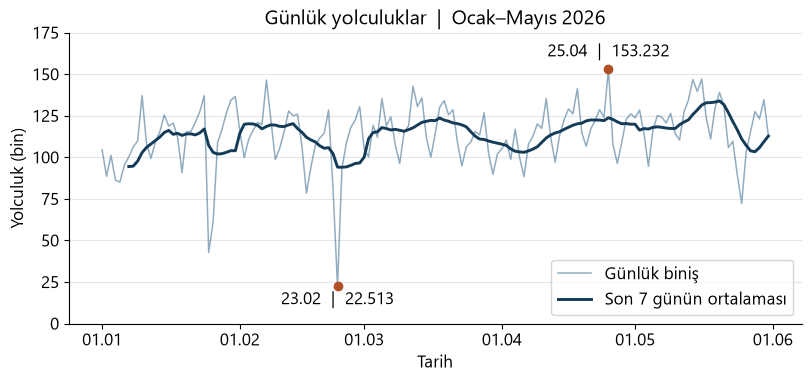

In [9]:
peak_day = day.loc[day.trip_count.idxmax()]
low_day = day.loc[day.trip_count.idxmin()]
fig, ax = plt.subplots(figsize=(8, 3.7), layout="constrained")
ax.plot(day.pickup_date, day.trip_count / 1_000, color=BLUE, alpha=0.5, linewidth=1.1, label="Günlük biniş")
ax.plot(day.pickup_date, day.trailing_7d_avg / 1_000, color="#143b58",
        linewidth=2.1, label="Son 7 günün ortalaması")
ax.legend(loc="lower right")
for row, offset in ((peak_day, 9), (low_day, -13)):
    pos = row.pickup_date, row.trip_count / 1_000
    ax.scatter(*pos, color=ORANGE, zorder=3)
    ax.annotate(f"{row.pickup_date:%d.%m}  |  {tr_int(row.trip_count)}", pos,
                xytext=(0, offset), textcoords="offset points", ha="center")
ax.set(title="Günlük yolculuklar  |  Ocak–Mayıs 2026", xlabel="Tarih", ylabel="Yolculuk (bin)", ylim=(0, 175))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
ax.grid(axis="y")
show_figure(fig)

**23 Şubat dönemin en düşük günü.** Düşüş, 22–23 Şubat’taki kar fırtınası ve 23 Şubat öğlene kadar yürürlükte kalan araç trafiği kısıtlamasıyla ilişkili olabilir. Central Park’ta yaklaşık 50 cm kar ölçüldü. Aşağıdaki tablo diğer pazartesilerle farkı gösterir. [NWS kar raporu](https://www.weather.gov/okx/20260222_23), [New York Belediyesi kararı](https://www.nyc.gov/content/dam/nycgov/mayors-office/downloads/pdf/executive-orders/2026/eeo-3.pdf)

In [10]:
low_date = pd.Timestamp("2026-02-23")
mondays = day.loc[day["pickup_date"].dt.dayofweek.eq(0)].set_index("pickup_date")["trip_count"]
other_mondays = mondays.drop(index=low_date)
display(pd.DataFrame({
    "Karşılaştırma": ["23 Şubat", "Diğer pazartesiler"],
    "Gün sayısı": [1, len(other_mondays)],
    "Günlük ortalama biniş": [tr_int(mondays.loc[low_date]), tr_int(other_mondays.mean())],
}).set_index("Karşılaştırma"))


,Gün sayısı,Günlük ortalama biniş
Karşılaştırma,,
23 Şubat,1,22.513
Diğer pazartesiler,20,93.592


### 25 Nisan’daki artış ne zaman ve nerede oldu?

Aşağıdaki saat ve bölge sayımları iki yöntemle de temiz veriden üretildi. 25 Nisan’ı Ocak–Mayıs dönemindeki **diğer 21 cumartesinin ortalamasıyla** karşılaştırdık.

25 Nisan’daki artış, o günkü yağış ve Car-Free Earth Day etkinliğiyle ilişkili olabilir. Etkinlik 10.00–16.00 arasında düzenlendi. Central Park’ta gün sonunda **34,5 mm** yağış ölçüldü. [NYC DOT etkinlik bilgisi](https://www.nyc.gov/html/dot/html/pedestrians/earthday.shtml), [NOAA günlük ölçümü](https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&endDate=2026-04-30&format=pdf&startDate=2026-04-01&stations=USW00094728)

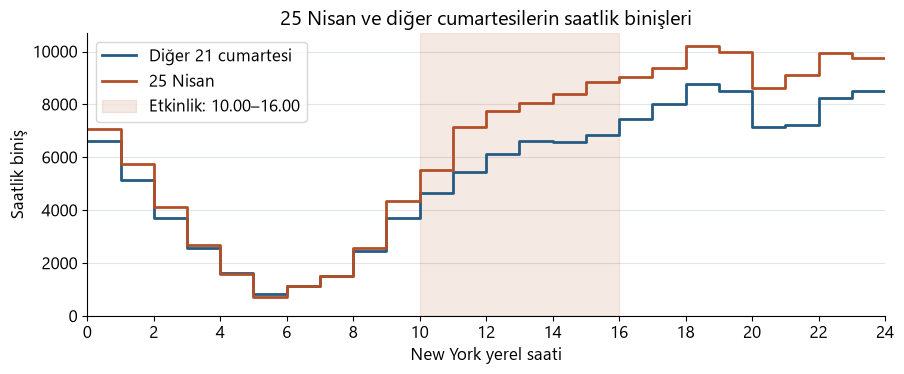

,Süre (saat),Diğer cumartesiler,25 Nisan,Ek biniş,Saat başına ek biniş
Saat,,,,,
00.00–09.59,10,29.343,31.514,2.171,217
10.00–15.59,6,36.279,45.695,9.416,1.569
16.00–23.59,8,63.885,76.023,12.138,1.517


,Diğer 21 cumartesi ort.,25 Nisan,Fark
"Biniş bölgesi, 10.00–15.59",,,
Diğer Manhattan,24.269,31.707,7.438
Upper East Side North,1.821,2.712,891
Upper East Side South,1.971,2.805,834
Diğer bölgeler,1.744,2.364,620
JFK ve LaGuardia,1.718,1.902,184
Broadway çevresi (6 bölge),4.757,4.205,-552
Manhattan toplamı,32.817,41.429,8.612


In [11]:
by_date_hour = (saturdays.groupby(["pickup_date", "pickup_hour"])["trip_count"]
                .sum().unstack(fill_value=0))
peak_date = pd.Timestamp("2026-04-25")
ordinary = by_date_hour.drop(index=peak_date).mean()
peak_counts = by_date_hour.loc[peak_date]
assert peak_counts.sum() == 153_232 and len(by_date_hour) == 22
peak_profile = pd.DataFrame({"Diğer 21 cumartesi": ordinary, "25 Nisan": peak_counts})
# Extend the 23.00 bin to midnight so each hourly total spans its full interval.
peak_profile.loc[24] = peak_profile.loc[23]
ax = peak_profile.plot(figsize=(9.2, 3.9), color=[BLUE, ORANGE], linewidth=2,
                       drawstyle="steps-post")
ax.axvspan(10, 16, alpha=0.12, color=ORANGE, label="Etkinlik: 10.00–16.00")
ax.set(title="25 Nisan ve diğer cumartesilerin saatlik binişleri",
       xlabel="New York yerel saati", ylabel="Saatlik biniş", ylim=(0, None), xlim=(0, 24))
ax.set_xticks(range(0, 25, 2))
ax.legend()
ax.grid(axis="y")
plt.tight_layout()
plt.show()

periods = [("00.00–09.59", range(10)), ("10.00–15.59", range(10, 16)), ("16.00–23.59", range(16, 24))]
period_table = []
for label, hours in periods:
    actual = peak_counts.loc[list(hours)].sum()
    expected = ordinary.loc[list(hours)].sum()
    extra = actual - expected
    period_table.append([label, len(hours), tr_int(expected), tr_int(actual),
                         tr_int(extra), tr_int(extra / len(hours))])
display(pd.DataFrame(period_table, columns=[
    "Saat", "Süre (saat)", "Diğer cumartesiler", "25 Nisan", "Ek biniş",
    "Saat başına ek biniş",
]).set_index("Saat"))

event_hours = saturdays.loc[saturdays["pickup_hour"].between(10, 15)]
area_count = event_hours.groupby(["area", event_hours["pickup_date"].eq(peak_date)])["trip_count"].sum().unstack(fill_value=0)
area_count[False] = area_count[False] / 21
area_count["Fark"] = area_count[True] - area_count[False]
manhattan_areas = ["Diğer Manhattan", "Upper East Side North",
                   "Upper East Side South", "Broadway çevresi (6 bölge)"]
manhattan_total = area_count.loc[manhattan_areas].sum()
assert round(manhattan_total["Fark"]) == 8_612
area_count = area_count.sort_values("Fark", ascending=False)
area_count.loc["Manhattan toplamı"] = manhattan_total
area_count = area_count.rename(columns={False: "Diğer 21 cumartesi ort.", True: "25 Nisan"})
display(area_count.map(tr_int).rename_axis(index="Biniş bölgesi, 10.00–15.59", columns=None))


Bu saatlerde Manhattan’da diğer 21 cumartesinin ortalamasına göre yaklaşık **8.612** ek biniş görüldü. Broadway çevresinden seçilen altı TLC bölgesinde ortalama **4.757** binişken o gün **4.205** biniş vardı. Bölge sınırları kapanan sokakların sınırlarıyla bire bir örtüşmez. Bu karşılaştırma, yağış ve etkinliğin ayrı etkilerini belirlemez.

Broadway çevresi karşılaştırmasında kullanılan TLC bölgeleri Flatiron (90), Garment District (100), Midtown South (164), Penn Station/Madison Sq West (186), Times Sq/Theatre District (230) ve Union Sq (234) olarak seçildi. Bunlar etkinlik güzergâhının çevresinden seçilmiş taksi bölgeleridir.

<a id="pik-gun-kontrolu"></a>

#### 25 Nisan farklı karşılaştırmalarda da zirve mi?

Bir önceki hafta alışılmadık olabilir. Bu yüzden haftanın aynı gününü koruyarak üç dayanak kullandık. Ortanca, karşılaştırma grubundaki aşırı yüksek ve düşük günlerden ortalamaya göre daha az etkilenir.

In [12]:
saturday_totals = by_date_hour.sum(axis=1)
peak_total = saturday_totals.loc[peak_date]
other_saturdays = saturday_totals.drop(peak_date)
assert len(other_saturdays) == 21 and peak_total > other_saturdays.max()

baselines = pd.Series({
    "Önceki cumartesi (18 Nisan)": saturday_totals.loc[peak_date - pd.Timedelta(days=7)],
    "En yakın 4 cumartesi (iki önce, iki sonra)": saturday_totals.reindex(
        peak_date + pd.to_timedelta([-14, -7, 7, 14], unit="D")
    ).mean(skipna=False),
    "Diğer 21 cumartesinin ortancası": other_saturdays.median(),
}, name="Karşılaştırma binişi")
assert baselines.notna().all()

comparison = baselines.to_frame()
comparison["Ek biniş"] = peak_total - baselines
comparison["Artış"] = (100 * (peak_total / baselines - 1)).map(lambda v: f"+%{tr_dec(v, 1)}")
for column in ("Karşılaştırma binişi", "Ek biniş"):
    comparison[column] = comparison[column].map(tr_int)
display(comparison.rename_axis("25 Nisan ile karşılaştırılan"))
display(Markdown(
    f"**25 Nisan, 22 cumartesi arasında 1. sırada.** "
    f"Üç karşılaştırmada da {tr_int(peak_total)} biniş en yüksek. "
    "Bu kontrol artışın karşılaştırma seçimine bağlı olmadığını gösterir. "
    "Yolculuk kayıtlarında yolcunun seçim nedeni yer almadığı için etkinlik veya yağışın payı ölçülemez. "
    "[TLC veri sözlüğü](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)"
))

,Karşılaştırma binişi,Ek biniş,Artış
25 Nisan ile karşılaştırılan,,,
Önceki cumartesi (18 Nisan),141.356,11.876,"+%8,4"
"En yakın 4 cumartesi (iki önce, iki sonra)",132.934,20.298,"+%15,3"
Diğer 21 cumartesinin ortancası,128.600,24.632,"+%19,2"


**25 Nisan, 22 cumartesi arasında 1. sırada.** Üç karşılaştırmada da 153.232 biniş en yüksek. Bu kontrol artışın karşılaştırma seçimine bağlı olmadığını gösterir. Yolculuk kayıtlarında yolcunun seçim nedeni yer almadığı için etkinlik veya yağışın payı ölçülemez. [TLC veri sözlüğü](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)

### Window (pencere hesabı) hangi bilgiyi ekliyor?

Pencere günlük tablonun **151 tarihini korur**. `rowsBetween(-6, 0)` bugünü ve önceki altı satırı kapsar. Sorgudaki `count(...) == 7` koşulu, pencere tam dolana kadar ortalamayı boş bırakır. **7 Ocak** ilk tam penceredir. `lag(7)` için ilk yedi gün boştur, **8 Ocak** ilk karşılaştırma günüdür. Tarihler kesintisiz olduğu için yedi satır önce, yedi gün öncedir.

`trip_count` (günlük biniş sayısı) üzerinden çalışan iki pencere ifadesi:

```python
ordered = Window.orderBy("pickup_date")
trailing = ordered.rowsBetween(-6, 0)
onceki_hafta = F.lag("trip_count", 7).over(ordered)
ortalama_7_gun = F.when(
    F.count("trip_count").over(trailing) == 7,
    F.avg("trip_count").over(trailing),
)
```

`partitionBy` kullanılmadığından Spark bu pencereyi tek bölümde işler. Pencereye gelen veri günlük sayımın 151 satırıdır.

24 Nisan satırında pencere **18–24 Nisan** arasını kapsar. Ertesi satıra geçince **18 Nisan çıkar ve 25 Nisan girer**. Kesikli ok, `lag(7)` ile yedi gün önceki biniş sayısının hangi satıra eklendiğini gösterir.

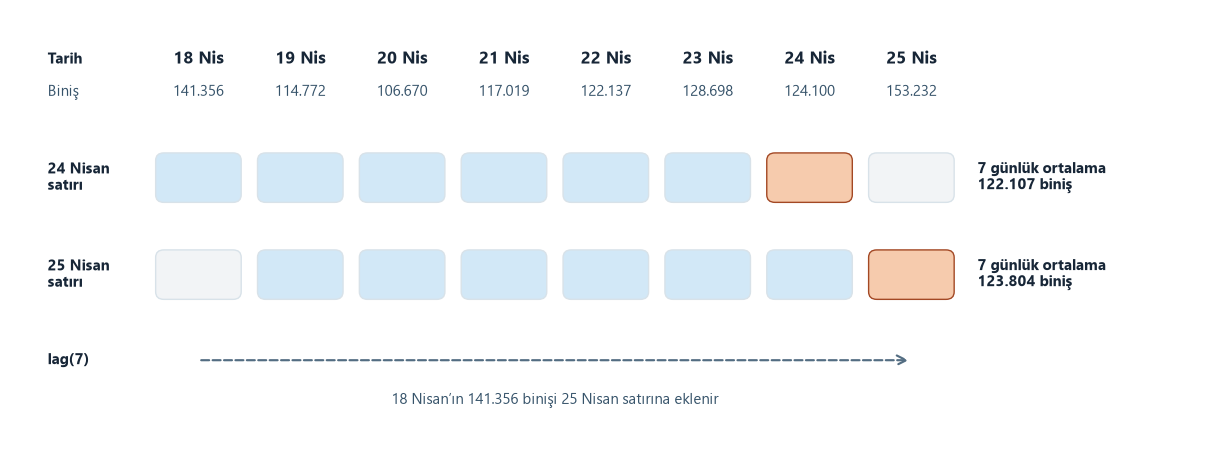

Renkli kutular ortalamaya giren günleri, turuncu kutu hesabın yazıldığı günü gösterir. 25 Nisan için **866.628 ÷ 7 = 123.804 biniş**.

In [13]:
from matplotlib.patches import FancyBboxPatch

april = day.loc[day["pickup_date"].between("2026-04-18", "2026-04-25")].reset_index(drop=True)
assert len(april) == 8
last = april.iloc[-1]
assert last["previous_week_trips"] == april.iloc[0]["trip_count"]
assert last["trailing_7d_avg"] == april.iloc[1:]["trip_count"].mean()

fig, ax = plt.subplots(figsize=(12.0, 4.6), layout="constrained")
ax.set(xlim=(-1.85, 9.85), ylim=(0, 4.75))
ax.set_axis_off()
for i, row in enumerate(april.itertuples()):
    ax.text(i, 4.18, f"{row.pickup_date.day} Nis", ha="center", color="#172637",
            fontsize=12, weight="bold")
    ax.text(i, 3.84, tr_int(row.trip_count), ha="center", color="#36536A", fontsize=10.5)
ax.text(-1.48, 4.18, "Tarih", fontsize=11, color="#172637", weight="bold")
ax.text(-1.48, 3.84, "Biniş", fontsize=11, color="#36536A")

for stop, y in ((6, 2.98), (7, 1.96)):
    current = april.iloc[stop]
    ax.text(-1.48, y, f"{current['pickup_date'].day} Nisan\nsatırı", va="center",
            fontsize=11, weight="bold", color="#172637")
    for i in range(len(april)):
        included = stop - 6 <= i <= stop
        fill = "#F6CBAD" if i == stop else "#D2E8F7" if included else "#F2F4F6"
        edge = "#A34824" if i == stop else "#D8E2E9"
        ax.add_patch(FancyBboxPatch((i - .39, y - .23), .78, .46,
                                    boxstyle="round,pad=.03,rounding_size=.08",
                                    facecolor=fill, edgecolor=edge, linewidth=1))
    ax.text(7.65, y, f"7 günlük ortalama\n{tr_int(current['trailing_7d_avg'])} biniş",
            va="center", fontsize=10.7, weight="bold", color="#172637")

ax.text(-1.48, 1.06, "lag(7)", color="#172637", fontsize=11, weight="bold", va="center")
ax.annotate("", xy=(7, 1.06), xytext=(0, 1.06),
            arrowprops={"arrowstyle": "->", "linestyle": "--", "lw": 1.55,
                        "color": "#536D82", "mutation_scale": 17})
ax.text(3.5, .60, f"18 Nisan’ın {tr_int(last['previous_week_trips'])} binişi 25 Nisan satırına eklenir",
        ha="center", fontsize=11, color="#36536A")
show_figure(fig)
display(Markdown(
    f"Renkli kutular ortalamaya giren günleri, turuncu kutu hesabın yazıldığı günü gösterir. "
    f"25 Nisan için **{tr_int(april.iloc[1:]['trip_count'].sum())} ÷ 7 = "
    f"{tr_int(last['trailing_7d_avg'])} biniş**."
))


In [14]:
def gun_tablosu(frame):
    return pd.DataFrame({
        "Tarih": frame["pickup_date"].dt.strftime("%d.%m.%Y"),
        "Biniş": frame["trip_count"].map(tr_int),
        "7 gün önce": frame["previous_week_trips"].map(lambda x: "—" if pd.isna(x) else tr_int(x)),
        "Son 7 günün ort.": frame["trailing_7d_avg"].map(lambda x: "—" if pd.isna(x) else tr_int(x)),
        "Haftalık değişim": frame["week_change_pct"].map(lambda x: "—" if pd.isna(x) else ("−" if x < 0 else "+" if x > 0 else "") + "%" + tr_dec(abs(x), 1)),
    }).set_index("Tarih")

display(gun_tablosu(day.head(8)))
display(gun_tablosu(day.loc[day["pickup_date"].between("2026-04-18", "2026-04-25")]))


,Biniş,7 gün önce,Son 7 günün ort.,Haftalık değişim
Tarih,,,,
01.01.2026,104.527,—,—,—
02.01.2026,88.641,—,—,—
03.01.2026,101.197,—,—,—
04.01.2026,86.266,—,—,—
05.01.2026,85.088,—,—,—
06.01.2026,95.187,—,—,—
07.01.2026,100.191,—,94.442,—
08.01.2026,106.233,104.527,94.686,"+%1,6"


,Biniş,7 gün önce,Son 7 günün ort.,Haftalık değişim
Tarih,,,,
18.04.2026,141.356,135.435,120.181,"+%4,4"
19.04.2026,114.772,112.074,120.566,"+%2,4"
20.04.2026,106.670,97.077,121.937,"+%9,9"
21.04.2026,117.019,113.052,122.504,"+%3,5"
22.04.2026,122.137,122.444,122.460,"−%0,3"
23.04.2026,128.698,129.069,122.407,"−%0,3"
24.04.2026,124.100,126.195,122.107,"−%1,7"
25.04.2026,153.232,141.356,123.804,"+%8,4"


In [15]:
sorgulari_goster([spark_queries.daily_trip_counts, spark_queries.daily_window_metrics])


**PySpark**

```python
def daily_trip_counts(trips: DataFrame) -> DataFrame:
    """Count pickups per New York calendar date, earliest first."""
    return (
        trips.withColumn("pickup_date", F.to_date("tpep_pickup_datetime"))
        .groupBy("pickup_date")
        .count()
        .withColumnRenamed("count", "trip_count")
        .orderBy("pickup_date")
    )

def daily_window_metrics(daily: DataFrame) -> DataFrame:
    """Compare calendar days and compute a full trailing seven-day average."""
    ordered = Window.orderBy("pickup_date")
    trailing = ordered.rowsBetween(-6, 0)
    return (
        daily.withColumn("previous_week_trips", F.lag("trip_count", 7).over(ordered))
        .withColumn("trailing_7d_avg", F.when(F.count("trip_count").over(trailing) == 7,
                                               F.avg("trip_count").over(trailing)))
        .withColumn("week_change_pct", F.when(F.col("previous_week_trips") > 0,
                    100.0 * (F.col("trip_count") - F.col("previous_week_trips")) / F.col("previous_week_trips")))
        .orderBy("pickup_date")
    )
```

<a id="bolge-analizi"></a>

## Bölge

**En çok biniş hangi bölgede?** `PULocationID` (biniş bölgesi kodu) ile sayıyoruz, `lookup` (TLC bölge sözlüğü) ile bölge adını ekliyoruz.

```python
zone_lookup = lookup.select(
    F.col("LocationID").cast("int").alias("PULocationID"),
    F.col("Borough").alias("borough"),
    F.col("Zone").alias("pickup_zone"),
)
counts = trips.groupBy("PULocationID").count().withColumnRenamed("count", "trip_count")
counts.join(F.broadcast(zone_lookup), "PULocationID", "left")
```

**Sonuç:** Central Park’ın doğusundaki **237 kodlu Upper East Side South**, **815.297** binişle ilk sırada.

Upper East Side’ın geçmişte de yoğun taksi binişi görülen bir bölge olması bu sonuçla ilişkili olabilir. TLC’nin önceki raporu daha geniş Upper East Side bölgesini kapsar. [TLC 2020 Factbook](https://www.nyc.gov/assets/tlc/downloads/pdf/2020-tlc-factbook.pdf)

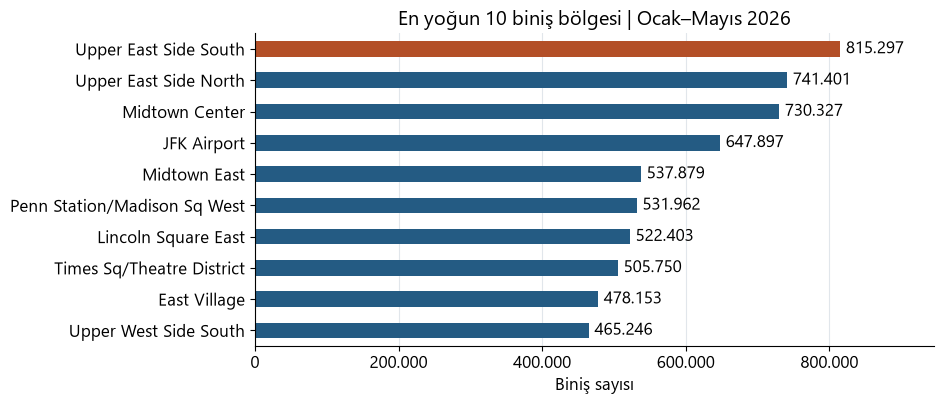

,Resmî TLC adı,İlçe,Türkçe konum,Biniş
TLC kodu,,,,
237,Upper East Side South,Manhattan,Yukarı Doğu Yakası’nın güney kesimi,815.297
236,Upper East Side North,Manhattan,Yukarı Doğu Yakası’nın kuzey kesimi,741.401
161,Midtown Center,Manhattan,Midtown’ın merkez kesimi,730.327
132,JFK Airport,Queens,John F. Kennedy Havalimanı,647.897
162,Midtown East,Manhattan,Midtown’ın doğu kesimi,537.879
186,Penn Station/Madison Sq West,Manhattan,Penn İstasyonu ve Madison Square Garden çevresi,531.962
142,Lincoln Square East,Manhattan,Lincoln Meydanı’nın doğusu,522.403
230,Times Sq/Theatre District,Manhattan,Times Meydanı ve Tiyatro Bölgesi,505.750
79,East Village,Manhattan,Manhattan’ın doğusunda East Village,478.153


In [16]:
konum = {
    237: "Yukarı Doğu Yakası’nın güney kesimi", 236: "Yukarı Doğu Yakası’nın kuzey kesimi",
    161: "Midtown’ın merkez kesimi", 132: "John F. Kennedy Havalimanı",
    162: "Midtown’ın doğu kesimi", 186: "Penn İstasyonu ve Madison Square Garden çevresi",
    142: "Lincoln Meydanı’nın doğusu", 230: "Times Meydanı ve Tiyatro Bölgesi",
    79: "Manhattan’ın doğusunda East Village", 239: "Yukarı Batı Yakası’nın güney kesimi",
    138: "LaGuardia Havalimanı", 7: "Queens’in kuzeybatısında Astoria",
    70: "Queens’te LaGuardia’nın güneyindeki East Elmhurst",
}
top = zone.head(10).copy()
top["Türkçe konum"] = top["PULocationID"].map(konum)
axes = top.iloc[::-1].plot.barh(x="pickup_zone", y="trip_count", figsize=(9.6, 4.2),
                              color=[BLUE] * 9 + [ORANGE], legend=False)
axes.set(title="En yoğun 10 biniş bölgesi | Ocak–Mayıs 2026", xlabel="Biniş sayısı", ylabel="")
axes.xaxis.set_major_formatter(lambda v, p: tr_int(v))
axes.set_xlim(0, top["trip_count"].max() * 1.16)
axes.bar_label(axes.containers[0], labels=top["trip_count"].iloc[::-1].map(tr_int), padding=4)
axes.grid(axis="x")
plt.tight_layout()
plt.show()
display(top.assign(trip_count=top["trip_count"].map(tr_int)).rename(columns={
    "PULocationID": "TLC kodu", "pickup_zone": "Resmî TLC adı",
    "borough": "İlçe", "trip_count": "Biniş",
}).set_index("TLC kodu")[["Resmî TLC adı", "İlçe", "Türkçe konum", "Biniş"]])


### Harita ve kapsam

Notebook’taki kayıtlı harita **17.210.743** binişi kapsıyor. Kullanılan GeoJSON dosyasında **57 (Corona)** ve **105 (Governor’s, Ellis ve Liberty adaları)** kodlarına karşılık gelen geometri bulunmadı. Bu kodlardaki **212 + 6 = 218** biniş harita dışında kaldı. **17.210.961** binişlik genel toplam bu kayıtları içeriyor. [NYC Taxi Zones sınırları](https://catalog.data.gov/dataset/nyc-taxi-zones)

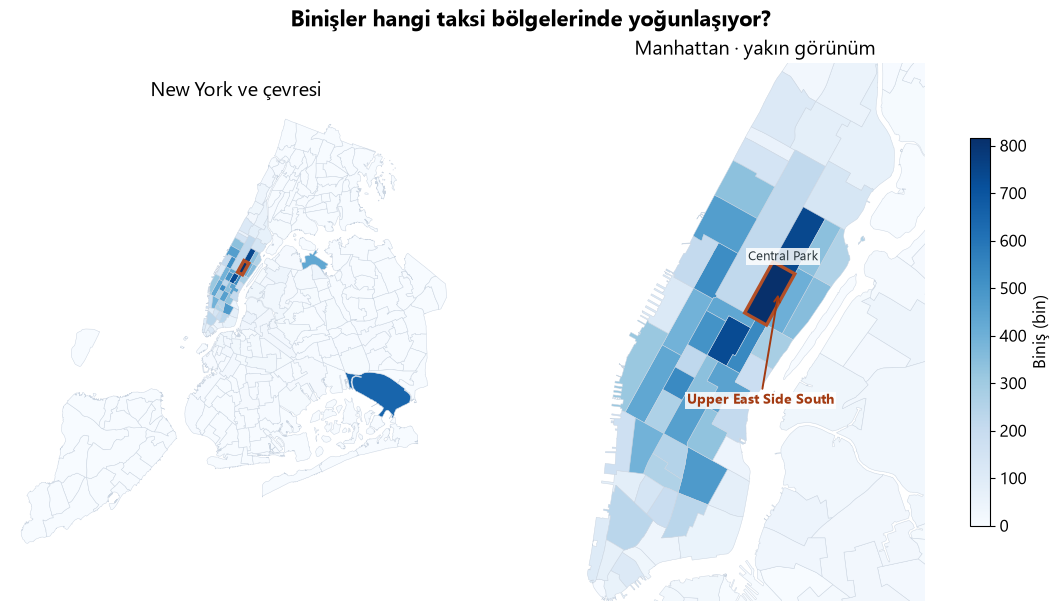

Haritada gösterilen: 17.210.743 / 17.210.961 yolculuk


,Haritada eşleşmeyen bölge,Biniş
TLC kodu,,
57,Corona,212
105,Governor's Island/Ellis Island/Liberty Island,6


In [17]:
import json
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
from matplotlib.patches import Polygon
from IPython.display import Image, display

geometry_file = root / "data" / "raw" / "taxi_zones.geojson"
map_name = "16_s3_pickup_map.png"

if geometry_file.exists():
    shapes = json.loads(geometry_file.read_text(encoding="utf-8"))["features"]
    counts = zone.set_index("PULocationID").trip_count
    peak_id = int(counts.idxmax())
    norm = Normalize(0, counts.max() / 1_000)
    shapes_by_id = {}
    for feature in shapes:
        zone_id = int(feature["properties"]["locationid"])
        geometry = feature["geometry"]
        polygons = geometry["coordinates"]
        if geometry["type"] == "Polygon":
            polygons = [polygons]
        shapes_by_id.setdefault(zone_id, []).extend(polygon[0] for polygon in polygons)

    assert peak_id in shapes_by_id
    mapped = int(counts.reindex(shapes_by_id, fill_value=0).sum())
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 6), layout="constrained")
    for ax in axes:
        patches, values = [], []
        for zone_id, outlines in shapes_by_id.items():
            for outline in outlines:
                patches.append(Polygon(outline, closed=True))
                values.append(counts.get(zone_id, 0) / 1_000)
        collection = PatchCollection(patches, cmap="Blues", norm=norm,
                                     edgecolor="#CBD5E1", linewidth=0.35)
        collection.set_array(values)
        ax.add_collection(collection)
        for outline in shapes_by_id[peak_id]:
            ax.add_patch(Polygon(outline, closed=True, fill=False, edgecolor=ORANGE, linewidth=2.4))
        ax.set_aspect(1.32)
        ax.set_axis_off()

    axes[0].set(title="New York ve çevresi", xlim=(-74.27, -73.68), ylim=(40.48, 40.93))
    axes[1].set(title="Manhattan · yakın görünüm", xlim=(-74.02, -73.92), ylim=(40.70, 40.82))
    axes[1].annotate("Central Park", (-73.972, 40.776), color="#263238", fontsize=9,
                     bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none", "pad": 1.5})
    axes[1].annotate("Upper East Side South", xy=(-73.963, 40.769), xytext=(-73.990, 40.744),
                     arrowprops={"arrowstyle": "->", "color": "#a33a11", "lw": 1.4},
                     color="#a33a11", fontsize=10, fontweight="bold",
                     bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none", "pad": 1.5})
    fig.suptitle("Binişler hangi taksi bölgelerinde yoğunlaşıyor?", fontsize=16, fontweight="bold")
    fig.colorbar(collection, ax=axes, shrink=0.72, label="Biniş (bin)")
    show_figure(fig)
    print(f"Haritada gösterilen: {tr_int(mapped)} / {tr_int(counts.sum())} yolculuk")
    missing = zone.loc[~zone["PULocationID"].isin(shapes_by_id)]
    assert mapped + missing["trip_count"].sum() == counts.sum()
    display(missing[["PULocationID", "pickup_zone", "trip_count"]].rename(columns={
        "PULocationID": "TLC kodu", "pickup_zone": "Haritada eşleşmeyen bölge",
        "trip_count": "Biniş",
    }).set_index("TLC kodu"))
else:
    display(Markdown("GeoJSON olmadan kayıtlı harita gösteriliyor."))
    display(Image(filename=str(figures / map_name)))


### Queens’te %80 eşiğine nasıl ulaşıldı?

`partitionBy("borough")` her ilçeyi ayrı alır. Spark, bölgeleri biniş sırasına koyup biriken sayıyı hesaplar.

**Bu pencere ilk bölgeden başlar ve her satırda bir bölge büyür.** Önceki grafikteki yedi günlük pencere ise her adımda yedi gün kalır. Aşağıdaki tabloda ilk üç bölge %78,42’de kalır ve dördüncü bölge eklenince pay %80,88’e çıkar.

`5 × biriken biniş ≥ 4 × ilçe toplamı` kontrolü, en az %80 şartını bölme yapmadan sınar. Böylece karar, gösterimdeki yüzde yuvarlamasından etkilenmez.

Grafikteki her nokta o sıraya kadar eklenen bölgelerin toplam payını gösterir. İlk üç bölge eşik çizgisinin altında kalır. **Dördüncü bölgeyle %80,88’e ulaşılır.**

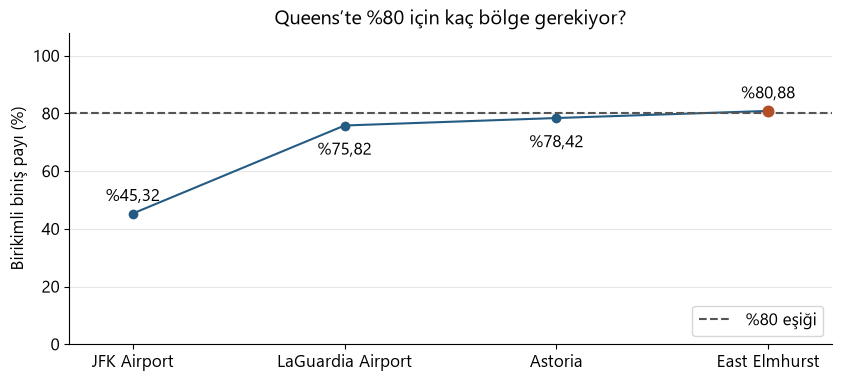

,Biriken biniş,Birikimli biniş payı,Kapsanan bölge
Eklenen bölge,,,
JFK Airport ve LaGuardia Airport,1.083.894,"%75,82",2/69
Astoria,1.120.952,"%78,42",3/69
East Elmhurst,1.156.215,"%80,88",4/69


,İlçe binişi,%80 için bölge,Biniş kaydı olan bölge,Kapsanan bölge oranı,Birikimli biniş payı
İlçe,,,,,
Queens,1.429.497,4,69,"%5,80","%80,88"
Brooklyn,490.455,23,61,"%37,70","%80,56"
Staten Island,1.576,8,19,"%42,11","%84,58"
Manhattan,15.212.024,30,67,"%44,78","%81,06"
Bronx,77.332,24,43,"%55,81","%81,09"


,Biniş
Beş NYC ilçesi dışındaki bölge,
Newark Airport,77


In [18]:
queen_zones = zone.loc[zone["borough"].eq("Queens")]
top4 = queen_zones.head(4)
shares = top4["trip_count"].cumsum().div(queen_zones["trip_count"].sum()).mul(100)
queens_result = spark_tables["zone_concentration"].set_index("borough").loc["Queens"]
assert int(queens_result["zones_to_80pct"]) == 4
assert shares.iloc[2] < 80 <= shares.iloc[3]
assert abs(shares.iloc[3] - queens_result["cumulative_pct"]) < 1e-8

fig, ax = plt.subplots(figsize=(8.3, 3.7), layout="constrained")
ax.plot(range(1, 5), shares, color=BLUE, marker="o")
ax.axhline(80, color="#555555", linestyle="--", label="%80 eşiği")
ax.scatter([4], [shares.iloc[-1]], color=ORANGE, s=58, zorder=3)
ax.set(title="Queens’te %80 için kaç bölge gerekiyor?",
       ylabel="Birikimli biniş payı (%)", ylim=(0, 108), xlim=(0.7, 4.3))
ax.set_xticks(range(1, 5), top4["pickup_zone"].tolist())
for rank, share in enumerate(shares, 1):
    offset = -21 if rank in (2, 3) else 9
    ax.annotate(f"%{tr_dec(share)}", (rank, share), xytext=(0, offset),
                textcoords="offset points", ha="center")
ax.grid(axis="y")
ax.legend(loc="lower right")
show_figure(fig)
steps = top4.assign(biriken_binis=top4["trip_count"].cumsum()).iloc[1:].copy()
steps["Birikimli biniş payı"] = steps["biriken_binis"].div(queen_zones["trip_count"].sum()).mul(100).map(lambda x: "%" + tr_dec(x))
steps["Kapsanan bölge"] = [f"{n}/{len(queen_zones)}" for n in (2, 3, 4)]
names = top4["pickup_zone"].tolist()
steps["Eklenen bölge"] = [" ve ".join(names[:2]), *names[2:]]
steps["Biriken biniş"] = steps["biriken_binis"].map(tr_int)
display(steps[["Eklenen bölge", "Biriken biniş", "Birikimli biniş payı", "Kapsanan bölge"]].set_index("Eklenen bölge"))

concentration = spark_tables["zone_concentration"]
display(concentration.assign(
    borough_total=concentration["borough_total"].map(tr_int),
    cumulative_pct=concentration["cumulative_pct"].map(lambda x: "%" + tr_dec(x)),
    observed_zones_pct=concentration["observed_zones_pct"].map(lambda x: "%" + tr_dec(x)),
)[["borough", "borough_total", "zones_to_80pct", "observed_zones", "observed_zones_pct",
   "cumulative_pct"]].rename(columns={
    "borough": "İlçe", "borough_total": "İlçe binişi", "zones_to_80pct": "%80 için bölge",
    "observed_zones": "Biniş kaydı olan bölge", "observed_zones_pct": "Kapsanan bölge oranı",
    "cumulative_pct": "Birikimli biniş payı",
}).set_index("İlçe"))
outside = zone.loc[~zone["borough"].isin(kiyas.BOROUGHS), ["pickup_zone", "trip_count"]]
assert concentration["borough_total"].sum() + outside["trip_count"].sum() == zone["trip_count"].sum()
display(outside.rename(columns={"pickup_zone": "Beş NYC ilçesi dışındaki bölge",
                                "trip_count": "Biniş"}).set_index("Beş NYC ilçesi dışındaki bölge"))


Queens’te dört bölge, binişlerin **%80,88’ini** kapsıyor. Bu dört bölge, biniş kaydı olan **69 bölgenin %5,8’i**. İlçe eşiği beş NYC ilçesi içinde hesaplanır. Staten Island satırının dayanağı **1.576** temiz biniştir.

**Bölge koduna ad nasıl ekleniyor?**

| Biniş sayımındaki satır | 265 satırlık bölge sözlüğündeki eşleşme | Birleştirme sonrası |
| --- | --- | --- |
| 237 → 815.297 biniş | 237 → Upper East Side South, Manhattan | Upper East Side South, Manhattan → 815.297 biniş |

Spark önce binişleri bölge koduna göre sayar. Ardından `broadcast` (yayınlama) ile 265 satırlık TLC sözlüğünü eşleştirmeyi yapan görevlere sunar. Sol birleştirme, sözlükte eşleşmesi bulunmayan sayım satırlarını da korur.

In [19]:
sorgulari_goster([spark_queries.zone_trip_counts, spark_queries.zone_concentration])


**PySpark**

```python
def zone_trip_counts(trips: DataFrame, zones: DataFrame) -> DataFrame:
    """Count pickups by zone ID and attach the TLC zone and borough names."""
    lookup = zones.select(
        F.col("LocationID").cast("int").alias("PULocationID"),
        F.col("Borough").alias("borough"),
        F.col("Zone").alias("pickup_zone"),
    )
    counts = trips.groupBy("PULocationID").count().withColumnRenamed("count", "trip_count")
    return counts.join(F.broadcast(lookup), "PULocationID", "left").orderBy(
        F.desc("trip_count"), F.asc("PULocationID")
    )

def zone_concentration(zones: DataFrame) -> DataFrame:
    """Rank recorded zones and find the first prefix containing at least 80%."""
    districts = ("Manhattan", "Queens", "Brooklyn", "Bronx", "Staten Island")
    borough = Window.partitionBy("borough")
    ranked = borough.orderBy(F.desc("trip_count"), F.asc("PULocationID"))
    cumulative = ranked.rowsBetween(Window.unboundedPreceding, Window.currentRow)
    return (
        zones.filter(F.col("borough").isin(*districts) & ~F.col("PULocationID").isin(264, 265))
        .withColumn("borough_total", F.sum("trip_count").over(borough))
        .withColumn("observed_zones", F.count("*").over(borough))
        .withColumn("zone_rank", F.row_number().over(ranked))
        .withColumn("cumulative_trips", F.sum("trip_count").over(cumulative))
        .withColumn("cumulative_pct", 100.0 * F.col("cumulative_trips") / F.col("borough_total"))
        .withColumn("zones_to_80pct", F.min(F.when(
            5 * F.col("cumulative_trips") >= 4 * F.col("borough_total"), F.col("zone_rank")
        )).over(borough))
        .filter(F.col("zone_rank") == F.col("zones_to_80pct"))
        .withColumn("observed_zones_pct", 100.0 * F.col("zones_to_80pct") / F.col("observed_zones"))
        .orderBy("observed_zones_pct")
    )
```

### Bölge birleştirmesinde broadcast ve shuffle karşılaştırması

Aynı temiz yolculuk verisi iki yöntemde de önce `PULocationID` (biniş bölgesi kodu) ile sayıldı. **260 sayım satırı**, **265 satırlı TLC bölge sözlüğü** ile aynı kod üzerinden `left join` kullanılarak birleştirildi. `left join`, sayım tarafındaki satırları korur.

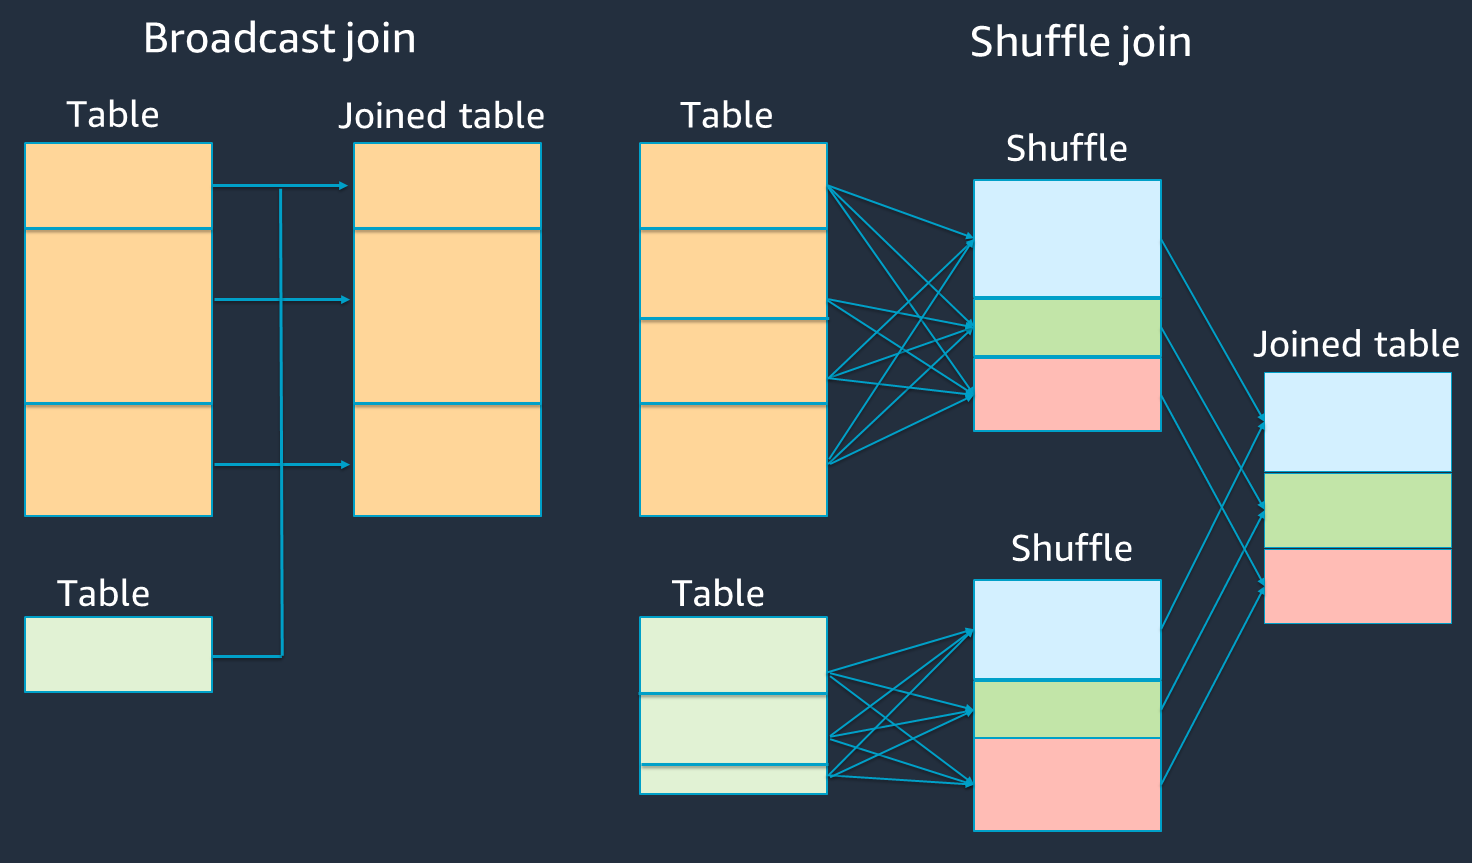

**AWS görselini bizim verimizle okuyalım.** Görsel iki yöntemi genel olarak anlatır; bizim deneyimizde gruplama sonrası iki tablo da küçüktür. Küçük tablo TLC sözlüğü, diğer tablo bölge başına sayımdır. `broadcast` (yayınlama), her görevin sözlüğe erişmesini sağlar. `shuffle` (veriyi bölümler arasında yeniden dağıtma) kullanan sort-merge birleştirmede ise iki tarafta aynı bölge kodları aynı bölümlere getirilir ve sıralanır. Bu deney tek bilgisayarda yapıldı.

**Gruplama ile eşleştirme ayrı adımlardır.** İlk `groupBy` aşaması aynı bölge kodunun ara sayımlarını bir araya getirir. Broadcast birleştirme, bu ilk gruplamadan çıkan 260 sayım satırına bölge adını eklerken sayım tarafını eşleştirme için yeniden dağıtma ihtiyacını kaldırır.

Kaynak: [AWS, Optimize shuffles](https://docs.aws.amazon.com/prescriptive-guidance/latest/tuning-aws-glue-for-apache-spark/optimize-shuffles.html). Görsel değiştirilmeden kullanılmıştır. AWS dokümantasyonu: [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/); [AWS site koşulları](https://aws.amazon.com/terms/).

**İki birleştirme sorgusu**

```python
# counts: önceden hesaplanmış bölge başına yolculuk sayısı
# lookup: LocationID, PULocationID olarak adlandırılmış TLC sözlüğü
broadcast_sonuc = counts.join(F.broadcast(lookup), "PULocationID", "left")
shuffle_sonuc = counts.hint("merge").join(
    lookup.hint("merge"), "PULocationID", "left"
)
```

**Spark hangi planı seçti?** Aşağıdaki satırlar aynı temiz veride, birleştirme sorguları çalıştırıldıktan sonra alındı. İki planın 260 sonuç satırı eşleşti. Karşılaştırmada yalnızca birleştirme planı gösteriliyor. Sort-merge, iki girişi aynı anahtara göre sıralar. Bu planda sayım tarafı anahtara göre zaten bölümlendiği için birleştirme öncesindeki yeni `Exchange` satırı sözlük tarafında görünür.

**Shuffle ölçümü için yapılan ayrı koşu.** Dört turda da birleştirme girdilerindeki shuffle yazımı broadcast için **0 bayt**, sort-merge için **20.242 bayt** çıktı. Bu sayaç, broadcast sözlüğünün kopyalanmasını veya sorgunun başka adımlarını ölçmez.

In [20]:
display(Markdown("\n\n".join(
    f"**{name}**\n\n```text\n" + "\n".join(rows["Gerçek Spark planında görülen satır"]) + "\n```"
    for name, rows in join_plans.groupby("Yöntem", sort=False)
)))

**Broadcast**

```text
*(2) BroadcastHashJoin [PULocationID#2129], [PULocationID#2242], LeftOuter, BuildRight, false
BroadcastExchange HashedRelationBroadcastMode(List(cast(input[0, int, false] as bigint)),false), [plan_id=1657]
```

**Sort-merge**

```text
*(4) SortMergeJoin [PULocationID#2129], [PULocationID#2242], LeftOuter
*(1) Sort [PULocationID#2129 ASC NULLS FIRST], false, 0
*(3) Sort [PULocationID#2242 ASC NULLS FIRST], false, 0
Exchange hashpartitioning(PULocationID#2242, 200), ENSURE_REQUIREMENTS, [plan_id=1698]
```

#### Ayrı süre deneyinin sonucu

İki sonuç da `trip_count` azalan ve `PULocationID` artan sıralamayla alındı. Deneyde Spark planı **BroadcastHashJoin** ve **SortMergeJoin** olarak kontrol edildi. İki ölçümde de otomatik broadcast ve uyarlamalı sorgu yürütme (AQE) kapalıydı. Yöntem, `broadcast` veya `merge` talimatıyla seçildi.

| Tur | Broadcast | Shuffle (sort merge) | Sonuç |
| --- | ---: | ---: | --- |
| 1 | 2,847 sn | 3,378 sn | Eşleşti |
| 2 | 2,863 sn | 3,364 sn | Eşleşti |
| 3 | 2,765 sn | 3,261 sn | Eşleşti |
| 4 | 2,762 sn | 3,346 sn | Eşleşti |
| **Ortanca** | **2,806 sn** | **3,355 sn** | **Eşleşti** |

- `local[2]`, 3 GB sürücü belleği ve 200 shuffle bölüm ayarı kullanıldı.
- Her yöntem iki kez ısıtıldı. Sonra dört tur ölçüldü; ilk çalışan yöntem değiştirildi.
- Sayım ve sözlük önceden önbelleğe alındı. Süre birleştirme, sıralama ve küçük sonucun alınmasını kapsar; veri okuma ve ilk gruplama süreye dahil değildir.
- Dört turda bütün satırlar eşleşti; sayımlar toplamı **17.210.961** idi.
- Broadcast bu deneyde daha kısa sürdü. Gruplama sonrası iki tablo da küçüktür; süre farkı tüm büyük veri problemlerine genellenemez.


Bu deneyde birleştirme türünü değiştirdik. Sonuç kontrolündeki `local[2]` / `local[4]` tablosunda ise görev yuvası sayısını değiştirip bölge sayımı da dahil olmak üzere altı işlemi ayrı ayrı ölçtük.

[Bu süre deneyini yeniden çalıştır](#sureyi-yeniden-olc)

Bu süreler önbellekteki 260 sayım satırı ile 265 sözlük satırına aittir. Ayarlar ve ölçülen işlemler `local[2]` / `local[4]` tablosundan farklıdır. Makineler arası ağ aktarımı ölçülmedi. Bölüm sayısı ve görev zamanlamasının süre farkına etkisi ayrı ölçülmedi.

<a id="odeme-analizi"></a>

## Ödeme

**En sık görülen ödeme kategorisi hangisi?** `payment_type` (ödeme türü) gruplamasındaki sayım satırı:

```python
trips.groupBy("payment_type").agg(
    F.count("*").alias("trip_count")
)
```

**Sonuç:** Kredi kartı **11.180.868** yolculukla, toplamın **%64,96**’sını oluşturuyor.

TLC kurallarına göre yolcular sarı taksilerde kartla ödeme hakkına sahiptir. Kartın neden daha sık seçildiği bu veride yer almaz. [TLC yolcu hakları](https://www.nyc.gov/site/tlc/passengers/yellow-taxi-passenger-bill-of-rights.page)

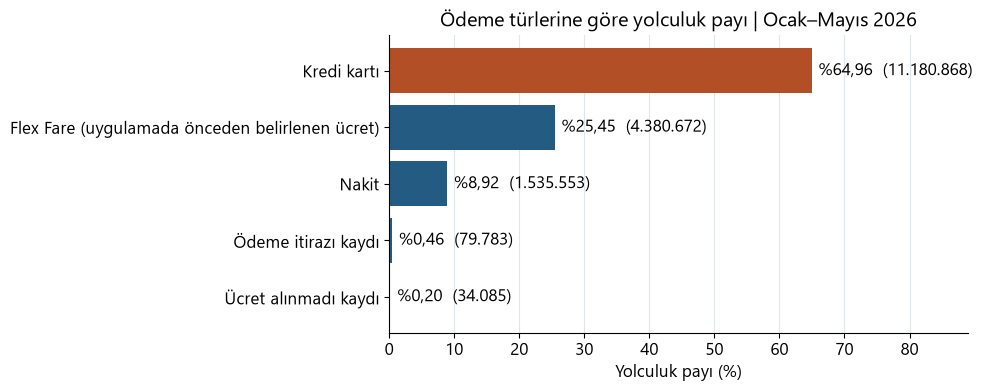

In [21]:
odeme_etiket = {
    0: "Flex Fare (uygulamada önceden belirlenen ücret)", 1: "Kredi kartı", 2: "Nakit",
    3: "Ücret alınmadı kaydı", 4: "Ödeme itirazı kaydı",
}
pay_view = payment.assign(etiket=payment["payment_type"].map(odeme_etiket)).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.7, 3.8), layout="constrained")
bars = ax.barh(pay_view["etiket"], pay_view["share_pct"],
               color=[ORANGE if k == 1 else BLUE for k in pay_view["payment_type"]])
ax.bar_label(bars, labels=[f"%{tr_dec(r.share_pct)}  ({tr_int(r.trip_count)})"
                           for r in pay_view.itertuples()], padding=5)
ax.set(title="Ödeme türlerine göre yolculuk payı | Ocak–Mayıs 2026", xlim=(0, 89), xlabel="Yolculuk payı (%)")
ax.grid(axis="x")
show_figure(fig)


| TLC kodu | Kullanım durumu |
| --- | --- |
| **0 — Flex Fare** | TLC’nin resmî Flex Fare kategorisidir. Lisanslı taksi uygulaması yolculuktan önce bağlayıcı bir fiyat sunar. |
| **1 — Credit card** | Ödeme kart işlemi olarak kaydedilir. |
| **2 — Cash** | Ödeme nakit kaydedilir. Kart işlemi başarısız olursa yolcu başka kart veya nakit kullanabilir. |
| **3 — No charge** | Ücret alınmadı olarak işaretlenmiş kayıttır. TLC toplantı tutanağındaki bir sürücü örneğinde yolcu ödeme yapmadan araçtan inmiştir. |
| **4 — Dispute** | Ücret veya ödeme uyuşmazlığı olarak işaretlenmiş kayıttır. Örneğin yolcu talep edilen tutara itiraz edebilir. |
| **5 — Unknown / 6 — Voided trip** | Ödeme biçiminin bilinmediği veya kaydın iptal edildiği durumlardır. Bu temiz veri döneminde görünmez. |

**Kod 3 ve 4:** Temiz veride sırasıyla **34.085** ve **79.783** kayıt var. Bu kayıtların hepsinde `total_amount` pozitif. Temizlik kuralı sıfır ve negatif tutarları kapsam dışı bıraktı. TLC, ödeme reddedilse bile taksimetredeki tutarın kayıt altına alınmasını öngörüyor. Kod ve kayıtlı tutar, ödeme yapılmamasının sebebini ya da itirazın sonucunu açıklamaz. [TLC veri sözlüğü](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf) · [TLC Flex Fare tanımı](https://www.nyc.gov/site/tlc/businesses/e-hail-providers.page) · [TLC sürücü kuralları §80-17](https://www.nyc.gov/assets/tlc/downloads/pdf/rule_book_current_chapter_80.pdf) · [TLC toplantı tutanağı](https://www.nyc.gov/assets/tlc/downloads/About/commission_meeting_transcript/transcript_04_25_2019.pdf) · [TLC yolcu SSS](https://www.nyc.gov/site/tlc/passengers/passenger-frequently-asked-questions.page)

### Ödeme payı, kart tutarı ve kayıtlı bahşiş

**Ödeme payı nasıl çıkıyor?** `groupBy("payment_type")` kayıtları beş ödeme satırına özetler. Ardından `sum("trip_count").over(Window.partitionBy())` bu beş satırın tamamından ortak paydayı hesaplar ve her ödeme satırına ekler. Boş `partitionBy()` beş özet satırını tek pencereye alır. Bu adım, ham yolculuk satırları gruplandıktan sonra çalışır.

| Kredi kartı satırı | Beş ödeme satırının toplamı | Kredi kartının yolculuk payı |
| ---: | ---: | ---: |
| 11.180.868 yolculuk | 17.210.961 yolculuk | %64,96 |

Grafikteki **%64,96 yolculuk payıdır**. Kart kategorisinde ortalama `total_amount` **29,05 USD**. Pozitif temel ücretli ve kayıtlı bahşişi sıfır veya üstü olan **11.180.868** kart kaydında, **toplam kayıtlı bahşiş ÷ toplam temel ücret = %23,50**. Bu ikinci oran, tutarlar üzerinden hesaplanır. Flex Fare (kod 0) ayrı bir kategoridir; burada hesaplanan kart bahşiş oranına dahil edilmez. Nakit bahşiş TLC tarafından bu veri alanında kaydedilmez. [TLC tutar ve bahşiş alanları sözlüğü](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)

**İki örnek yolculuk.** Temel ücretler 10 ve 30 dolar, iki bahşiş de 3 dolar olsun. Yolculuk yüzdelerinin ortalaması (%30 + %10) ÷ 2 = **%20**. Notebook’taki yöntem toplamları böler: 6 ÷ 40 = **%15**. Gerçek kart verisindeki **%23,50** ikinci yöntemle hesaplanır.

In [22]:
odeme_tablosu = pd.DataFrame({
    "TLC kodu": payment["payment_type"],
    "Kategori": payment["payment_type"].map(odeme_etiket),
    "Yolculuk": payment["trip_count"].map(tr_int),
    "Yolculuk payı": payment["share_pct"].map(lambda v: "%" + tr_dec(v)),
    "Ort. kayıtlı toplam tutar (USD)": payment["mean_total_amount"].map(tr_dec),
    "Bahşiş hesabına giren kayıt": payment["tip_eligible_trips"].map(tr_int),
    "Ağırlıklı kayıtlı bahşiş": payment["weighted_tip_pct"].map(lambda v: "—" if pd.isna(v) else "%" + tr_dec(v)),
})
display(odeme_tablosu.set_index("TLC kodu"))


,Kategori,Yolculuk,Yolculuk payı,Ort. kayıtlı toplam tutar (USD),Bahşiş hesabına giren kayıt,Ağırlıklı kayıtlı bahşiş
TLC kodu,,,,,,
1,Kredi kartı,11.180.868,"%64,96","29,05",11.180.868,"%23,50"
0,Flex Fare (uygulamada önceden belirlenen ücret),4.380.672,"%25,45","32,63",0,—
2,Nakit,1.535.553,"%8,92","24,87",0,—
4,Ödeme itirazı kaydı,79.783,"%0,46","27,76",0,—
3,Ücret alınmadı kaydı,34.085,"%0,20","23,93",0,—


In [23]:
sorgulari_goster([spark_queries.payment_trip_counts])


**PySpark**

```python
def payment_trip_counts(trips: DataFrame) -> DataFrame:
    """Count payment codes and calculate their share of all pickups."""
    labels = F.create_map(
        F.lit(0), F.lit("Flex Fare"),
        F.lit(1), F.lit("Credit card"),
        F.lit(2), F.lit("Cash"),
        F.lit(3), F.lit("No charge"),
        F.lit(4), F.lit("Dispute"),
        F.lit(5), F.lit("Unknown"),
        F.lit(6), F.lit("Voided trip"),
    )
    eligible = (F.col("payment_type") == 1) & (F.col("fare_amount") > 0) & (F.col("tip_amount") >= 0)
    counts = trips.groupBy("payment_type").agg(
        F.count("*").alias("trip_count"),
        F.avg("total_amount").alias("mean_total_amount"),
        F.count(F.when(eligible, 1)).alias("tip_eligible_trips"),
        F.sum(F.when(eligible, F.col("tip_amount"))).alias("eligible_tip_total"),
        F.sum(F.when(eligible, F.col("fare_amount"))).alias("eligible_fare_total"),
    )
    return (
        counts.withColumn("payment_label", labels[F.col("payment_type").cast("int")])
        .withColumn("share_pct", 100.0 * F.col("trip_count") / F.sum("trip_count").over(Window.partitionBy()))
        .withColumn("weighted_tip_pct", F.when(F.col("eligible_fare_total") > 0,
                    100.0 * F.col("eligible_tip_total") / F.col("eligible_fare_total")))
        .drop("eligible_tip_total", "eligible_fare_total")
        .orderBy(F.desc("trip_count"), F.asc("payment_type"))
    )
```

<a id="sonuc-kontrolu"></a>

## Sonuç kontrolü

Temiz girdide **17.210.961 yolculuk** var. Saat, gün, hafta günü × saat, bölge ve ödeme tablolarında yolculuk sayıları ayrı ayrı bu toplama ulaştı. İlçe başına %80 eşiği tablosu her ilçeden yalnızca eşik satırını gösterdiği için onun kontrolü farklıdır.

PySpark özetlerinin satır sayıları, toplamları ve günlük tarih aralığı kontrol edildi. Ödeme payları toplamı %100’dür.

In [24]:
display(pd.DataFrame([
    {
        "Özet": title,
        "Özet satırı": len(spark_tables[name]),
        "Yolculuk toplamı": (
            tr_int(spark_tables[name]["trip_count"].sum())
            if name != "zone_concentration" else "5 ilçe için eşik satırı"
        ),
    }
    for name, title in kiyas.SUMMARY_NAMES.items()
]).set_index("Özet"))

,Özet satırı,Yolculuk toplamı
Özet,,
Saat,24,17.210.961
Gün ve pencere,151,17.210.961
Hafta günü × saat,168,17.210.961
Biniş bölgesi,260,17.210.961
İlçede %80 eşiği,5,5 ilçe için eşik satırı
Ödeme,5,17.210.961


### Analizlerin local[2] ve local[4] süreleri

`local`, Spark’ın bu bilgisayarda çalışmasıdır. `local[2]` aynı anda en fazla iki, `local[4]` en fazla dört görev çalıştırır. Her iki ayarda **aynı beş Parquet dosyası ve 3 GB sürücü belleği** kullanıldı.

| İşlem | local[2] ortanca (sn) | local[4] ortanca (sn) | Sonuç |
| --- | ---: | ---: | --- |
| Saat | 0,676 | 0,453 | Eşleşti |
| Gün ve günlük pencere | 1,573 | 1,126 | Eşleşti |
| Hafta günü × saat | 1,276 | 1,047 | Eşleşti |
| Bölge sayımı ve birleştirme | 1,307 | 1,074 | Eşleşti |
| İlçede %80 bölge yoğunlaşması | 3,353 | 2,131 | Eşleşti |
| Ödeme | 1,202 | 1,012 | Eşleşti |

- **Süreye giren:** Sorguyu kurma ve `collect()` (küçük sonucu Python’a alma) ile bitirme. Her ayar üç kez ölçüldü. Her ölçümden önce altı işlem bir kez çalıştırılarak oturum ısıtıldı. İkinci turda önce `local[4]` çalıştırıldı.
- **Hazırlık:** Oturum açılışı, yolculuk verisini ve TLC sözlüğünü önbelleğe alma süreye dahil edilmedi. Bölge sayımı ölçülürken bölge sonucu önbellekte yoktu. İlçe yoğunlaşması ölçülürken 260 satırlık bölge sayımı hazırdı.
- **Gözlem:** `local[4]`, bu bilgisayarda **6/6 işlemde** daha kısa ortanca verdi. Hem sonuçların eşleştiği hem de bölge sorgusunun gerçekten gruplama ve birleştirme çalıştırdığı kontrol edildi.
- **Süre neden oynar?** Daha fazla görev yuvası, uygun sayıda veri bölümü varsa paralel çalışmayı artırabilir. İşletim sisteminin dosya önbelleği, JVM ısınması, bellek yönetimi ve arka plan yükü de turdan tura süreyi etkileyebilir. Bunların ayrı etkileri ölçülmedi.

<details>
<summary>Üç turun ayrı süreleri (saniye)</summary>

| İşlem | local[2] 1. tur | 2. tur | 3. tur | local[4] 1. tur | 2. tur | 3. tur |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Saat | 0,606 | 0,678 | 0,676 | 0,453 | 0,445 | 0,502 |
| Gün ve günlük pencere | 1,573 | 1,466 | 1,582 | 1,276 | 1,123 | 1,126 |
| Hafta günü × saat | 1,276 | 1,071 | 1,351 | 1,047 | 1,178 | 1,043 |
| Bölge sayımı ve birleştirme | 1,289 | 1,528 | 1,307 | 1,074 | 1,036 | 1,175 |
| İlçede %80 bölge yoğunlaşması | 3,353 | 3,473 | 3,295 | 2,131 | 2,121 | 2,205 |
| Ödeme | 1,151 | 1,202 | 1,294 | 1,094 | 0,979 | 1,012 |

</details>

[Bu süre deneyini yeniden çalıştır](#sureyi-yeniden-olc)

İlçede %80 hesabı bölge özeti üzerinde pencere ve sıralama adımları kullanır. Süreyi satır sayısı ve işlem adımları birlikte etkiler.

<a id="sureyi-yeniden-olc"></a>

### Süre deneyini yeniden çalıştır

Üstteki tablolar önceki ölçümün kayıtlı sonuçlarıdır. Yeni bir ölçüm için notebook’u proje ortamında baştan çalıştır. Bu bölümdeki son kod hücresinde seçeneği değiştirip yalnızca o hücreyi çalıştır:

| Seçenek | Yeniden ölçülen işlem |
| --- | --- |
| `"local"` | Tam veride altı sorgu, üçer tur `local[2]` ve `local[4]` |
| `"join"` | Hazır bölge sayımı ile TLC sözlüğünün birleştirilmesi, dört tur |
| `"ikisi"` | İki deney art arda |

Yeni süre tablosu bu hücrenin altında görünür. Program aynı sorgulardan çıkan sonuçları notebook’un doğrulanmış tablolarıyla karşılaştırır. Deneyler birkaç dakika sürebilir. Varsayılan `"kapali"` ayarı normal ders akışını hızlandırır.

Birleştirme deneyinde Spark’ın ölçtüğü shuffle yazımı da gösterilir. Tablo sadece birleştirmeye giren kollardaki yeniden dağıtımı kapsar. İlk gruplama, son sıralama ve broadcast verisinin kopyalanması bu sayaca dahil değildir.

In [25]:
OLCUM_ISLEMI_KODU = r"""
from pathlib import Path
from time import perf_counter
import json
import os
import sys

from src import aggregate_trips as q
from src import compare_aggregation as comparison
from src.spark_session import get_spark
import pandas as pd

folder = Path(__file__).parent

def measure(plan):
    started = perf_counter()
    query = plan()
    rows = query.collect()
    elapsed = perf_counter() - started
    return query, pd.DataFrame.from_records(rows, columns=query.columns), elapsed

def run_local(pair, cores):
    spark = get_spark("ogrenci-3-local-benchmark", driver_memory="3g", cores=str(cores))
    spark.sparkContext.setLogLevel("ERROR")
    trips = spark.read.parquet(*comparison.clean_parquet_files()).select(*comparison.TRIP_COLUMNS).persist()
    lookup = spark.read.option("header", True).csv(str(comparison.ZONE_LOOKUP_PATH)).persist()
    queries = {
        "hour": lambda: q.hourly_trip_counts(trips),
        "day": lambda: q.daily_window_metrics(q.daily_trip_counts(trips)),
        "pattern": lambda: q.weekday_hour_trip_counts(trips),
        "zone": lambda: q.zone_trip_counts(trips, lookup),
        "payment": lambda: q.payment_trip_counts(trips),
    }
    keys = list(queries)
    offset = pair - 1
    keys = keys[offset:] + keys[:offset]

    def one_round():
        tables, timings = {}, {}
        for key in keys:
            query, tables[key], timings[key] = measure(queries[key])
            if key == "zone":
                executed = query._jdf.queryExecution().executedPlan().toString()
                assert "HashAggregate" in executed and "BroadcastHashJoin" in executed
                assert not any("InMemoryTableScan" in line and "trip_count" in line
                               for line in executed.splitlines()), "Zone result was read from cache"
        zones = queries["zone"]().persist()
        try:
            assert zones.count() == 260
            _, tables["zone_concentration"], timings["zone_concentration"] = measure(
                lambda: q.zone_concentration(zones))
        finally:
            zones.unpersist(blocking=True)
        comparison.verify_full_scope(tables)
        return tables, timings

    try:
        assert spark.sparkContext.master == f"local[{cores}]"
        assert trips.count() == comparison.CLEAN_ROWS and lookup.count() == 265
        warm, _ = one_round()
        tables, timings = one_round()
        comparison.verify_reports(warm, tables)
        pd.to_pickle(tables, folder / f"{pair}-{cores}.pkl")
        (folder / f"{pair}-{cores}.json").write_text(json.dumps(timings))
        print(f"Pair {pair} local[{cores}] verified.", flush=True)
    finally:
        spark.stop()


def run_join():
    from pyspark.sql import functions as F

    spark = get_spark("ogrenci-3-join-benchmark", driver_memory="3g", cores="2")
    try:
        spark.sparkContext.setLogLevel("ERROR")
        for key, value in {
            "spark.sql.adaptive.enabled": "false",
            "spark.sql.autoBroadcastJoinThreshold": "-1",
            "spark.sql.shuffle.partitions": "200",
        }.items():
            spark.conf.set(key, value)
        counts = (spark.read.parquet(*comparison.clean_parquet_files())
                  .groupBy("PULocationID").count().withColumnRenamed("count", "trip_count").persist())
        lookup = (spark.read.option("header", True).csv(str(comparison.ZONE_LOOKUP_PATH))
                  .select(F.col("LocationID").cast("int").alias("PULocationID"),
                          F.col("Borough").alias("borough"), F.col("Zone").alias("pickup_zone"))
                  .persist())
        assert counts.count() == 260 and lookup.count() == 265

        def ordered_join(mode):
            if mode == "broadcast":
                joined = counts.join(F.broadcast(lookup), "PULocationID", "left")
            else:
                joined = counts.hint("merge").join(lookup.hint("merge"), "PULocationID", "left")
            return joined.orderBy(F.desc("trip_count"), F.asc("PULocationID"))

        def join_shuffle_bytes(plan, operator):
            def children(node):
                iterator = node.children().iterator()
                while iterator.hasNext():
                    yield iterator.next()

            def find_join(node):
                if node.nodeName() == operator:
                    return node
                for child in children(node):
                    result = find_join(child)
                    if result is not None:
                        return result
                return None

            def bytes_below(node):
                # Cached lookup and count preparation is outside the join.
                if node.nodeName() == "InMemoryTableScan":
                    return 0
                total = 0
                if node.nodeName() == "Exchange":
                    metric = node.metrics().get("shuffleBytesWritten")
                    if metric.isDefined():
                        total = metric.get().value()
                return total + sum(bytes_below(child) for child in children(node))

            join = find_join(plan)
            assert join is not None, operator
            return sum(bytes_below(child) for child in children(join))

        def compare_methods(order):
            measured = {}
            tables = {}
            operators = {"broadcast": "BroadcastHashJoin", "sort_merge": "SortMergeJoin"}
            for mode in order:
                query, table, elapsed = measure(lambda: ordered_join(mode))
                computed_plan = query._jdf.queryExecution().executedPlan()
                assert operators[mode] in computed_plan.toString()
                measured[f"{mode}_shuffle_bytes"] = join_shuffle_bytes(computed_plan, operators[mode])
                assert len(table) == 260 and table["trip_count"].sum() == comparison.CLEAN_ROWS
                tables[mode] = table
                measured[mode] = elapsed
            comparison.verify_reports({"zone": tables["broadcast"]}, {"zone": tables["sort_merge"]})
            return tables["broadcast"], measured

        methods = ("broadcast", "sort_merge")
        compare_methods(methods)
        compare_methods(methods[::-1])
        records = []
        baseline = None
        for turn in range(1, 5):
            actual, timings = compare_methods(methods if turn % 2 else methods[::-1])
            if baseline is None:
                baseline = actual
            comparison.verify_reports({"zone": baseline}, {"zone": actual})
            records.append(timings)
        pd.to_pickle({"zone": baseline}, folder / "join.pkl")
        (folder / "join.json").write_text(json.dumps(records))
    finally:
        spark.stop()

if sys.argv[1] == "local":
    run_local(int(sys.argv[2]), int(sys.argv[3]))
elif sys.argv[1] == "join":
    run_join()
else:
    raise ValueError("Bilinmeyen deney.")

"""

def sure_deneyini_calistir(deney):
    import json
    import subprocess
    import tempfile

    from pyspark import SparkContext

    if SparkContext._active_spark_context is not None:
        raise RuntimeError("Ölçümden önce açık Spark oturumunu spark.stop() ile kapat.")
    if deney not in {"local", "join", "ikisi"}:
        raise ValueError('Seçenekler: "kapali", "local", "join", "ikisi".')

    with tempfile.TemporaryDirectory(prefix="nyc-taxi-olcum-") as temporary:
        folder = Path(temporary)
        script = folder / "olcum_islemi.py"
        script.write_text(OLCUM_ISLEMI_KODU, encoding="utf-8")
        env = os.environ.copy()
        env["PYTHONPATH"] = os.pathsep.join(
            path for path in (str(root), env.get("PYTHONPATH")) if path
        )

        def run_child(*args):
            result = subprocess.run(
                [sys.executable, str(script), *map(str, args)],
                cwd=root, env=env, capture_output=True, text=True,
                encoding="utf-8", errors="replace",
            )
            if result.returncode:
                details = (result.stderr or result.stdout)[-2200:]
                raise RuntimeError(f"Ölçüm tamamlanamadı:\n{details}")

        if deney in {"local", "ikisi"}:
            runs = []
            for tur, order in enumerate(((2, 4), (4, 2), (2, 4)), start=1):
                for cores in order:
                    print(f"Tur {tur}, local[{cores}] ölçülüyor…", flush=True)
                    run_child("local", tur, cores)
                    output = folder / f"{tur}-{cores}"
                    kiyas.verify_reports(spark_tables, pd.read_pickle(output.with_suffix(".pkl")))
                    timings = json.loads(output.with_suffix(".json").read_text(encoding="utf-8"))
                    runs.extend({"Tur": tur, "Ayar": f"local[{cores}]", "İşlem": kiyas.SUMMARY_NAMES[key],
                                 "Saniye": seconds} for key, seconds in timings.items())
            raw = pd.DataFrame(runs)
            result = raw.pivot_table(index="İşlem", columns="Ayar", values="Saniye", aggfunc="median")
            display(Markdown("**Yeni ölçüm · local[2] ve local[4] ortancaları (saniye)**"))
            display(result.reindex(kiyas.SUMMARY_NAMES.values()).round(3))
            display(raw.pivot(index=["İşlem", "Tur"], columns="Ayar", values="Saniye").round(3))
            print("Altı sorgu ve altı koşudaki sonuç tabloları doğrulandı.")

        if deney in {"join", "ikisi"}:
            print("Broadcast ve sort-merge ölçülüyor…", flush=True)
            run_child("join")
            kiyas.verify_reports({"zone": spark_tables["zone"]}, pd.read_pickle(folder / "join.pkl"))
            records = json.loads((folder / "join.json").read_text(encoding="utf-8"))
            measurements = pd.DataFrame(records)
            result = measurements[["broadcast", "sort_merge"]].rename(columns={
                "broadcast": "Broadcast", "sort_merge": "Sort-merge"
            })
            result.index = pd.RangeIndex(1, len(result) + 1, name="Tur")
            result.loc["Ortanca"] = result.median()
            display(Markdown("**Yeni ölçüm · Broadcast ve sort-merge (saniye)**"))
            display(result.round(3))
            io = measurements[["broadcast_shuffle_bytes", "sort_merge_shuffle_bytes"]].rename(columns={
                "broadcast_shuffle_bytes": "Broadcast", "sort_merge_shuffle_bytes": "Sort-merge"
            })
            io.index = pd.RangeIndex(1, len(io) + 1, name="Tur")
            display(Markdown("**Birleştirme girdilerine ait shuffle yazımı (bayt)**"))
            display(io)
            print("İki plan doğrulandı ve 260 sonuç satırı eşleşti.")


In [26]:
deney = "kapali"
if deney != "kapali":
    sure_deneyini_calistir(deney)

<a id="canli-sorgu"></a>

### Canlı sorgu ve grafik

Önce notebook’un ilk kod hücresini çalıştırın. Sonra aşağıdaki hücrede `canli_sorgu = True` yapıp çalıştırın. `trips` temiz yolculuk tablosu, `lookup` TLC bölge sözlüğü, `zone_lookup` birleştirmeye hazır sözlüktür. `F`, `Window` ve `plt` ile sorgu ve grafik yazılabilir.

Grafik için Spark’ta küçük bir özet oluşturup yalnızca bu özeti `toPandas()` ile Python’a alın. İşlem tamamlandığında `spark.stop()` oturumu kapatır.

In [27]:
canli_sorgu = False

if canli_sorgu:
    spark = get_spark("ogrenci-3", driver_memory="3g", cores="2")
    spark.sparkContext.setLogLevel("ERROR")
    trips = spark.read.parquet(str(kiyas.CLEAN_DIR))
    lookup = spark.read.option("header", True).csv(str(kiyas.ZONE_LOOKUP_PATH))
    zone_lookup = lookup.select(
        F.col("LocationID").cast("int").alias("PULocationID"),
        F.col("Borough").alias("borough"),
        F.col("Zone").alias("pickup_zone"),
    )
    print("Hazır: trips (yolculuklar), lookup (ham sözlük), zone_lookup (birleştirme için).")
    print("Yolculuk sütunları:", ", ".join(trips.columns))

In [28]:
# Sorgu veya grafik kodu